# 中国股市股票尾盘动量研究

## 范文：Overnight Momentum, Informational Shocks, and Late-Informed Trading in China

### 将对研究指数的尾盘动量效益移步到具体的股票投资当中，研究其适用性。

## 0 数据准备

这一步将复制论文的2.1节的数据源内容。股票分钟数据仅从本地 D:\quantitative_data\mindata\stock_min\bfq_min 读取；日线、市值、交易日历、ST截面及沪深300指数行情仅通过本研究文件夹中-mysql_data的data_driven.py从局域网MySQL读取。局域网数据库没有沪深300历史成分表，因此按用户裁决仅使用本地沪深300指数行情作为比较基准，不构造或伪造历史成分股池。

### 0.1 数据读取函数

In [1]:
# 这里只封装本地文件和局域网 MySQL；不调用任何线上数据接口。
from pathlib import Path
import re
import sys

import numpy as np
import pandas as pd
from IPython.display import display
from sqlalchemy import text


# ------------------------------ 路径与研究口径
PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / "main.ipynb").exists():
    PROJECT_DIR = Path(r"D:\quantitative_project\复现工程\Intraday_Momentum_Hour_Predicts_company")

MINUTE_ROOT = Path(r"D:\quantitative_data\mindata\stock_minfq_min")
MYSQL_API_DIR = PROJECT_DIR.parent / "-mysql_data"
OUTPUT_DIR = PROJECT_DIR / "output_data"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_START = pd.Timestamp("2000-01-01")
SAMPLE_END = pd.Timestamp("2025-12-31")
MIN_LISTED_TRADING_DAYS = 244
MIN_CIRC_MV = 300_000.0  # stock_daily_basic.circ_mv 单位为万元，即人民币 30 亿元
HS300_CODE = "000300.SH"

if str(MYSQL_API_DIR) not in sys.path:
    sys.path.insert(0, str(MYSQL_API_DIR))
import data_driven as dd

data_client = dd.pro_api()


# ------------------------------ 局域网 MySQL 通用分页读取
def fetch_all(method, *, page_size=100_000, **kwargs):
    """分页调用 data_driven.py 的公开方法并返回完整 DataFrame。"""
    frames = []
    offset = 0
    while True:
        batch = method(limit=page_size, offset=offset, **kwargs)
        if batch.empty:
            break
        frames.append(batch)
        if len(batch) < page_size:
            break
        offset += len(batch)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def load_trade_calendar(start_date=SAMPLE_START, end_date=SAMPLE_END):
    """从局域网 MySQL 读取沪深市场开市日历。"""
    calendar = fetch_all(
        data_client.trade_cal,
        exchange="SSE",
        is_open=1,
        start_date=pd.Timestamp(start_date).strftime("%Y%m%d"),
        end_date=pd.Timestamp(end_date).strftime("%Y%m%d"),
        fields="cal_date",
    )
    if calendar.empty:
        raise RuntimeError("交易日历为空，请检查局域网 MySQL 的 trade_cal 数据。")
    dates = pd.DatetimeIndex(pd.to_datetime(calendar["cal_date"]).dt.normalize().unique())
    return dates.sort_values()


def load_hs300_benchmark(start_date=SAMPLE_START, end_date=SAMPLE_END):
    """从局域网 MySQL 读取沪深300日线，作为收益比较基准。"""
    frame = fetch_all(
        data_client.index_daily,
        ts_code=HS300_CODE,
        start_date=pd.Timestamp(start_date).strftime("%Y%m%d"),
        end_date=pd.Timestamp(end_date).strftime("%Y%m%d"),
        fields="ts_code,trade_date,open,high,low,close,pre_close,pct_chg",
    )
    if frame.empty:
        raise RuntimeError("局域网 MySQL 中没有沪深300指数日线。")
    frame["trade_date"] = pd.to_datetime(frame["trade_date"]).dt.normalize()
    frame = frame.sort_values("trade_date", ignore_index=True)
    if frame["trade_date"].duplicated().any():
        raise RuntimeError("沪深300指数日线存在重复交易日。")
    frame["benchmark_return"] = pd.to_numeric(frame["pct_chg"], errors="raise") / 100.0
    return frame


# ------------------------------ 本地分钟 CSV 读取
_MINUTE_COLUMN_MAP = {
    "时间": "trade_time",
    "名称": "name",
    "开盘价": "open",
    "收盘价": "close",
    "最高价": "high",
    "最低价": "low",
    "成交量": "vol",
    "成交额": "amount",
    "涨幅": "pct_chg",
    "振幅": "amplitude",
}
_MINUTE_DEFAULT_COLUMNS = [
    "trade_time", "ts_code", "name", "open", "close", "high", "low",
    "vol", "amount", "pct_chg", "amplitude",
]
_TS_CODE_RE = re.compile(r"^(?:(SH|SZ|BJ))?(\d{6})(?:\.(SH|SZ|BJ))?$", re.I)


def normalize_ts_code(value):
    """把 sh600000、600000.SH 等格式统一为 600000.SH。"""
    match = _TS_CODE_RE.fullmatch(str(value).strip())
    if match is None:
        raise ValueError("证券代码格式无效：{!r}".format(value))
    prefix, number, suffix = match.groups()
    exchange = suffix or prefix
    if exchange is None:
        exchange = "SH" if number.startswith(("5", "6", "9")) else "SZ"
    return "{}.{}".format(number, exchange.upper())


def minute_file(ts_code, year):
    code = normalize_ts_code(ts_code)
    number, exchange = code.split(".")
    local_code = exchange.lower() + number
    return MINUTE_ROOT / "{}_1min".format(int(year)) / "{}_{}.csv".format(local_code, int(year))


def read_stock_minute(ts_code, start_date, end_date, columns=None):
    """按股票和日期读取本地 1 分钟 CSV，只加载需要的列。"""
    code = normalize_ts_code(ts_code)
    start = pd.Timestamp(start_date).normalize()
    end = pd.Timestamp(end_date).normalize()
    if start > end:
        raise ValueError("start_date 不能晚于 end_date。")

    requested = list(columns) if columns is not None else list(_MINUTE_DEFAULT_COLUMNS)
    unknown = set(requested) - set(_MINUTE_DEFAULT_COLUMNS)
    if unknown:
        raise ValueError("未知分钟字段：{}".format(sorted(unknown)))

    needed = set(requested) | {"trade_time"}
    source_columns = [source for source, target in _MINUTE_COLUMN_MAP.items() if target in needed]
    frames = []
    checked_paths = []
    for year in range(start.year, end.year + 1):
        path = minute_file(code, year)
        checked_paths.append(path)
        if not path.exists():
            continue
        frame = pd.read_csv(path, encoding="utf-8-sig", usecols=source_columns)
        frame = frame.rename(columns=_MINUTE_COLUMN_MAP)
        frame["trade_time"] = pd.to_datetime(frame["trade_time"], errors="raise")
        frame = frame.loc[
            (frame["trade_time"] >= start)
            & (frame["trade_time"] < end + pd.Timedelta(days=1))
        ].copy()
        if not frame.empty:
            frame["ts_code"] = code
            frames.append(frame)

    if not frames:
        raise FileNotFoundError(
            "指定区间没有分钟数据；已检查：{}".format(", ".join(map(str, checked_paths)))
        )
    result = pd.concat(frames, ignore_index=True).sort_values("trade_time", ignore_index=True)
    return result.loc[:, requested]


print("本地数据函数初始化完成：{} 至 {}".format(SAMPLE_START.date(), SAMPLE_END.date()))

本地数据函数初始化完成：2000-01-01 至 2025-12-31


### 0.2 股票时段筛选

In [2]:
# 按照论文的2.1节，选择股票的时间面板；即得出股票纳入时间，退出时间，及其对应的交易日历。论文的过滤面是：必须有244个交易日，即在244个交易日后进行纳入股票池。在实际操作的股票中，新增过滤面：股票的流通市值必须为大于30亿rmb，且是非ST股票和非*ST股票。最终得出股票的纳入时间，退出时间，及其对应的交易日历，为stock_pool_list。
# 用户裁决：现有本地数据没有沪深300历史成分表，仅使用本地沪深300指数行情作为比较基准；不构造或伪造hs_stock_list。

import pyarrow as pa
import pyarrow.parquet as pq


def _read_minute_day_name_status(path):
    """读取年度分钟文件的实际交易日、名称缺失日及 ST/*ST 日期。"""
    observed_days = []
    invalid_name_days = []
    st_days = []
    for chunk in pd.read_csv(
        path,
        encoding="utf-8-sig",
        usecols=["时间", "名称"],
        chunksize=200_000,
    ):
        day_text = chunk["时间"].astype(str).str.slice(0, 10)
        names = chunk["名称"].astype("string")
        observed_days.extend(day_text.unique())
        invalid_name = names.isna() | names.str.strip().eq("")
        if invalid_name.any():
            invalid_name_days.extend(day_text.loc[invalid_name].unique())
        is_st = names.str.upper().str.contains("ST", regex=False, na=False)
        if is_st.any():
            st_days.extend(day_text.loc[is_st].unique())
    if not observed_days:
        raise RuntimeError("分钟文件没有数据行：{}".format(path))
    return (
        pd.DatetimeIndex(pd.to_datetime(pd.Index(observed_days).unique(), errors="raise")).sort_values(),
        pd.DatetimeIndex(pd.to_datetime(pd.Index(invalid_name_days).unique(), errors="raise")).sort_values(),
        pd.DatetimeIndex(pd.to_datetime(pd.Index(st_days).unique(), errors="raise")).sort_values(),
    )


def _local_stock_st_coverage(trading_calendar, end_date):
    """检查 MySQL stock_st 的本地覆盖期及中间缺口交易日。"""
    sql = text("""
        SELECT DISTINCT trade_date
        FROM stock_st
        WHERE trade_date <= :end_date
        ORDER BY trade_date
    """)
    with data_client._mysql_engine().connect() as connection:
        dates = pd.read_sql_query(sql, connection, params={"end_date": pd.Timestamp(end_date).date()})
    if dates.empty:
        raise RuntimeError("局域网 MySQL 的 stock_st 表为空。")
    covered = pd.DatetimeIndex(pd.to_datetime(dates["trade_date"]).dt.normalize().unique()).sort_values()
    coverage_start = covered.min()
    expected = pd.DatetimeIndex(trading_calendar)
    expected = expected[(expected >= coverage_start) & (expected <= pd.Timestamp(end_date))]
    missing_days = expected.difference(covered)
    return coverage_start, missing_days


def build_local_minute_st_calendar(candidates, trading_calendar, end_date):
    """用本地分钟名称补齐 ST；无法验证的股票日单独返回，供主流程保守剔除。"""
    cache = OUTPUT_DIR / "stock_st_from_local_minute_v3.parquet"
    audit_cache = OUTPUT_DIR / "stock_pool_unverified_local_v3.parquet"
    coverage_start, missing_days = _local_stock_st_coverage(trading_calendar, end_date)
    frame = candidates.loc[:, ["ts_code", "trade_date"]].copy()
    frame["trade_date"] = pd.to_datetime(frame["trade_date"]).dt.normalize()
    target = frame.loc[
        (frame["trade_date"] < coverage_start)
        | frame["trade_date"].isin(missing_days)
    ].drop_duplicates()
    if target.empty:
        result = pd.DataFrame(columns=["ts_code", "trade_date"])
        audit = pd.DataFrame(columns=["ts_code", "trade_date", "reason", "source_file"])
        result.to_parquet(cache, index=False)
        audit.to_parquet(audit_cache, index=False)
        return result, audit

    target["year"] = target["trade_date"].dt.year
    coverage = (
        target.groupby(["ts_code", "year"], as_index=False)["trade_date"]
        .agg(required_dates=list)
    )
    pieces = []
    audit_pieces = []
    total = len(coverage)
    for number, row in enumerate(coverage.itertuples(index=False), start=1):
        path = minute_file(row.ts_code, row.year)
        required_days = pd.DatetimeIndex(row.required_dates)
        if not path.exists():
            audit_pieces.append(pd.DataFrame({
                "ts_code": row.ts_code,
                "trade_date": required_days,
                "reason": "missing_minute_file",
                "source_file": str(path),
            }))
            continue
        observed_days, invalid_name_days, st_days = _read_minute_day_name_status(path)
        absent_days = required_days.difference(observed_days)
        invalid_required_days = required_days.intersection(invalid_name_days)
        if len(absent_days):
            audit_pieces.append(pd.DataFrame({
                "ts_code": row.ts_code,
                "trade_date": absent_days,
                "reason": "missing_minute_day",
                "source_file": str(path),
            }))
        if len(invalid_required_days):
            audit_pieces.append(pd.DataFrame({
                "ts_code": row.ts_code,
                "trade_date": invalid_required_days,
                "reason": "missing_stock_name",
                "source_file": str(path),
            }))
        verified_days = required_days.difference(absent_days.union(invalid_required_days))
        matched_st_days = verified_days.intersection(st_days)
        if len(matched_st_days):
            pieces.append(pd.DataFrame({"ts_code": row.ts_code, "trade_date": matched_st_days}))
        if number % 500 == 0 or number == total:
            print("本地 ST 扫描进度：{}/{}".format(number, total))

    if pieces:
        result = pd.concat(pieces, ignore_index=True).drop_duplicates(ignore_index=True)
    else:
        result = pd.DataFrame(columns=["ts_code", "trade_date"])
    if audit_pieces:
        audit = pd.concat(audit_pieces, ignore_index=True).drop_duplicates(ignore_index=True)
        audit = audit.sort_values(["trade_date", "ts_code", "reason"], ignore_index=True)
    else:
        audit = pd.DataFrame(columns=["ts_code", "trade_date", "reason", "source_file"])
    result.to_parquet(cache, index=False)
    audit.to_parquet(audit_cache, index=False)
    if not audit.empty:
        print("无法验证 ST 状态的股票日：{:,}，已从股票池保守剔除。".format(len(audit)))
        display(audit.groupby("reason").size().rename("股票-交易日数").to_frame())
    return result, audit


def _write_candidate_pool(cache, start_date, end_date, min_listed_days, min_circ_mv):
    """在 MySQL 端完成日龄、市值和已覆盖 ST 的筛选，并流式写入本地缓存。"""
    sql = text("""
        WITH open_days AS (
            SELECT
                cal_date,
                LAG(cal_date) OVER (ORDER BY cal_date) AS previous_open_date
            FROM trade_cal
            WHERE exchange = 'SSE'
              AND is_open = 1
              AND cal_date <= :end_date
        ),
        basic_history AS (
            SELECT
                b.ts_code,
                b.trade_date,
                LAG(b.trade_date) OVER (
                    PARTITION BY b.ts_code ORDER BY b.trade_date
                ) AS circ_mv_date,
                LAG(b.circ_mv) OVER (
                    PARTITION BY b.ts_code ORDER BY b.trade_date
                ) AS circ_mv_prev,
                ROW_NUMBER() OVER (
                    PARTITION BY b.ts_code ORDER BY b.trade_date
                ) - 1 AS listed_trading_days
            FROM stock_daily_basic AS b
            WHERE b.trade_date <= :end_date
              AND (b.ts_code LIKE '%%.SH' OR b.ts_code LIKE '%%.SZ')
        )
        SELECT
            h.ts_code,
            h.trade_date,
            c.previous_open_date,
            h.circ_mv_date,
            h.circ_mv_prev,
            h.listed_trading_days
        FROM basic_history AS h
        JOIN open_days AS c
          ON c.cal_date = h.trade_date
        LEFT JOIN stock_st AS s
          ON s.ts_code = h.ts_code AND s.trade_date = h.trade_date
        WHERE h.trade_date BETWEEN :start_date AND :end_date
          AND h.listed_trading_days >= :min_listed_days
          AND h.circ_mv_date = c.previous_open_date
          AND h.circ_mv_prev > :min_circ_mv
          AND s.ts_code IS NULL
        ORDER BY h.trade_date, h.ts_code
    """)
    params = {
        "start_date": pd.Timestamp(start_date).date(),
        "end_date": pd.Timestamp(end_date).date(),
        "min_listed_days": int(min_listed_days),
        "min_circ_mv": float(min_circ_mv),
    }
    temp_cache = cache.with_name(cache.stem + ".tmp.parquet")
    if temp_cache.exists():
        temp_cache.unlink()
    writer = None
    row_count = 0
    try:
        with data_client._mysql_engine().connect() as connection:
            chunks = pd.read_sql_query(sql, connection, params=params, chunksize=250_000)
            for chunk in chunks:
                for column in ("trade_date", "previous_open_date", "circ_mv_date"):
                    chunk[column] = pd.to_datetime(chunk[column]).dt.normalize()
                if not chunk["circ_mv_date"].equals(chunk["previous_open_date"]):
                    raise RuntimeError("发现流通市值日期不是严格前一开市日。")
                chunk["circ_mv_prev"] = pd.to_numeric(chunk["circ_mv_prev"], errors="raise")
                chunk["listed_trading_days"] = chunk["listed_trading_days"].astype("int32")
                table = pa.Table.from_pandas(chunk, preserve_index=False)
                if writer is None:
                    writer = pq.ParquetWriter(temp_cache, table.schema, compression="zstd")
                writer.write_table(table)
                row_count += len(chunk)
    finally:
        if writer is not None:
            writer.close()
    if row_count == 0:
        raise RuntimeError("股票池候选结果为空，请检查本地数据库覆盖期与筛选阈值。")
    temp_cache.replace(cache)


def build_stock_pool_daily(
    trading_calendar,
    start_date=SAMPLE_START,
    end_date=SAMPLE_END,
    min_listed_days=MIN_LISTED_TRADING_DAYS,
    min_circ_mv=MIN_CIRC_MV,
):
    """完全基于本地数据构建无未来函数的逐日股票池。"""
    final_cache = OUTPUT_DIR / "stock_pool_daily_local_v3.parquet"
    candidate_cache = OUTPUT_DIR / "stock_pool_candidates_local_v3.parquet"
    # 每次重建并复核本地数据，避免数据更新后静默复用旧资格结果。
    _write_candidate_pool(candidate_cache, start_date, end_date, min_listed_days, min_circ_mv)

    candidates = pd.read_parquet(candidate_cache)
    local_minute_st, unverified = build_local_minute_st_calendar(
        candidates, trading_calendar, end_date
    )
    excluded = pd.concat([
        local_minute_st[["ts_code", "trade_date"]],
        unverified[["ts_code", "trade_date"]],
    ], ignore_index=True).drop_duplicates(ignore_index=True)
    if not excluded.empty:
        excluded_keys = pd.MultiIndex.from_frame(excluded)
        candidate_keys = pd.MultiIndex.from_frame(candidates[["ts_code", "trade_date"]])
        candidates = candidates.loc[~candidate_keys.isin(excluded_keys)].copy()

    candidates = candidates.sort_values(["trade_date", "ts_code"], ignore_index=True)
    candidates.to_parquet(final_cache, index=False, compression="zstd")
    return candidates


def daily_to_interval_list(daily_pool, trading_calendar):
    """把逐日股票池压缩为纳入/退出区间，并保留每段对应交易日历。"""
    frame = daily_pool.loc[:, ["ts_code", "trade_date"]].drop_duplicates().copy()
    frame["trade_date"] = pd.to_datetime(frame["trade_date"]).dt.normalize()
    frame = frame.sort_values(["ts_code", "trade_date"], ignore_index=True)
    calendar_no = pd.Series(np.arange(len(trading_calendar)), index=pd.DatetimeIndex(trading_calendar))
    frame["_calendar_no"] = calendar_no.reindex(frame["trade_date"]).to_numpy()
    if frame["_calendar_no"].isna().any():
        raise ValueError("股票池包含不在本地交易日历中的日期。")

    new_interval = (
        frame["ts_code"].ne(frame["ts_code"].shift())
        | frame["_calendar_no"].sub(frame["_calendar_no"].shift()).ne(1)
    )
    frame["_interval_id"] = new_interval.cumsum()
    return (
        frame.groupby(["ts_code", "_interval_id"], sort=False)
        .agg(
            in_date=("trade_date", "first"),
            out_date=("trade_date", "last"),
            n_trade_days=("trade_date", "size"),
            trade_calendar=("trade_date", list),
        )
        .reset_index()
        .drop(columns="_interval_id")
        .sort_values(["in_date", "ts_code"], ignore_index=True)
    )


# ------------------------------ 正式构建
trade_calendar = load_trade_calendar(SAMPLE_START, SAMPLE_END)
stock_pool_daily = build_stock_pool_daily(
    trade_calendar,
    SAMPLE_START,
    SAMPLE_END,
)
stock_pool_list = daily_to_interval_list(stock_pool_daily, trade_calendar)
stock_pool_unverified = pd.read_parquet(OUTPUT_DIR / "stock_pool_unverified_local_v3.parquet")

hs300_benchmark = load_hs300_benchmark(SAMPLE_START, SAMPLE_END)
hs300_benchmark.to_parquet(OUTPUT_DIR / "hs300_benchmark_local.parquet", index=False)
hs_stock_list = None  # 本地没有历史成分数据，按用户裁决明确不构造代理成分股池

pool_summary = pd.DataFrame({
    "股票数": [stock_pool_daily["ts_code"].nunique()],
    "股票-交易日数": [len(stock_pool_daily)],
    "纳入区间数": [len(stock_pool_list)],
    "因本地分钟缺口剔除数": [len(stock_pool_unverified)],
    "首个交易日": [stock_pool_daily["trade_date"].min()],
    "最后交易日": [stock_pool_daily["trade_date"].max()],
}, index=["沪深A股筛选池"])
benchmark_summary = pd.DataFrame({
    "基准": [HS300_CODE],
    "首个交易日": [hs300_benchmark["trade_date"].min()],
    "最后交易日": [hs300_benchmark["trade_date"].max()],
    "交易日数": [len(hs300_benchmark)],
})
display(pool_summary)
display(stock_pool_list.head())
display(benchmark_summary)

无法验证 ST 状态的股票日：2,354,672，已从股票池保守剔除。


,股票-交易日数
reason,
missing_minute_file,2354672


,股票数,股票-交易日数,纳入区间数,因本地分钟缺口剔除数,首个交易日,最后交易日
沪深A股筛选池,4900,5930352,99431,2354672,2016-08-09,2025-12-31


,ts_code,in_date,out_date,n_trade_days,trade_calendar
0,000001.SZ,2016-08-09,2016-08-09,1,[2016-08-09 00:00:00]
1,000002.SZ,2016-08-09,2016-08-09,1,[2016-08-09 00:00:00]
2,000005.SZ,2016-08-09,2016-08-09,1,[2016-08-09 00:00:00]
3,000006.SZ,2016-08-09,2016-08-09,1,[2016-08-09 00:00:00]
4,000007.SZ,2016-08-09,2016-08-09,1,[2016-08-09 00:00:00]


,基准,首个交易日,最后交易日,交易日数
0,000300.SH,2002-01-04,2025-12-31,5817


## 1 Intraday Momentum at the Firm Level ( 对应文章3-4节 )

### 1.1 基线结果（3.1节 Baseline Results）

#### 1.1.1 半小时收益率面板构建


In [3]:
# 按照论文附录A.1的变量定义，从本地1分钟数据提取每只股票的日度锚点价格
# （前一交易日15:00收盘价，当日9:30开盘价，9:35/9:40/9:45/9:50/9:55/10:00、14:00、14:30、15:00的分钟收盘价），
# 计算以下收益率（1.1节基线与1.4/1.5节分解回归共用同一面板）：
#   r_1st          = P(10:00) / P(前一交易日收盘) - 1    第一个半小时收益率（含隔夜部分）
#   r_ov           = P(9:30开盘) / P(前一交易日收盘) - 1  隔夜收益率（盘前集合竞价决定）
#   r_9:35 … r_10:00 = P(锚点) / P(9:30开盘) - 1         开盘动量的六个替代口径（连续竞价阶段）
#   r_14_30        = P(14:30) / P(14:00) - 1             倒数第二个半小时收益率
#   r_last         = P(15:00) / P(14:30) - 1             最后半小时收益率（被解释变量）
# 恒等式：1 + r_1st = (1 + r_ov) × (1 + r_10:00)。
# 本地分钟bar按结束时间打标（09:30为首根集合竞价bar、15:00为末根），时点口径与论文一致。
# 分钟数据为不复权价格：除权除息日的 r_1st/r_ov 含有分红缺口，属于样本噪声（每股每年约一次），与论文一样不做额外处理。
# 回归样本与0.2节股票池（stock_pool_daily）取交集，保证无未来函数。
# 全量构建耗时较长，结果缓存至 output_data/stock_halfhour_returns_v2.parquet，重复运行直接读取缓存。

import pyarrow.csv as pv

_ANCHOR_TIMES = ("09:35:00", "09:40:00", "09:45:00", "09:50:00", "09:55:00",
                 "10:00:00", "14:00:00", "14:30:00", "15:00:00")
HALFHOUR_RETURN_CACHE = OUTPUT_DIR / "stock_halfhour_returns_v2.parquet"


def _extract_daily_anchor_close(path):
    """从年度分钟CSV提取每日锚点收盘价与9:30开盘价。"""
    table = pv.read_csv(
        path,
        read_options=pv.ReadOptions(encoding="utf-8-sig"),
        convert_options=pv.ConvertOptions(
            include_columns=["时间", "开盘价", "收盘价"],
            column_types={"时间": "string", "开盘价": "float64", "收盘价": "float64"},
        ),
    )
    frame = table.to_pandas()
    day = frame["时间"].str.slice(0, 10)
    hm = frame["时间"].str.slice(11)
    open_930 = pd.Series(
        frame.loc[hm == "09:30:00", "开盘价"].to_numpy(),
        index=day.loc[hm == "09:30:00"],
    )
    frame = frame.loc[hm.isin(_ANCHOR_TIMES)].copy()
    frame["hm"] = hm.loc[frame.index]
    frame["trade_date"] = day.loc[frame.index]
    wide = frame.pivot_table(index="trade_date", columns="hm", values="收盘价", aggfunc="last")
    wide["open_0930"] = open_930
    return wide


def build_halfhour_return_panel(stock_pool, cache=HALFHOUR_RETURN_CACHE):
    """按股票遍历本地分钟文件，计算与股票池对齐的日度半小时收益率面板。"""
    if cache.exists():
        return pd.read_parquet(cache)

    pool_by_stock = stock_pool.groupby("ts_code")["trade_date"].agg(["min", "max", set])
    pieces = []
    total = len(pool_by_stock)
    for number, (code, row) in enumerate(pool_by_stock.iterrows(), start=1):
        frames = []
        # 多读一年分钟文件，保证股票入池首日的“前一交易日收盘价”也能取到
        for year in range(row["min"].year - 1, row["max"].year + 1):
            path = minute_file(code, year)
            if path.exists():
                frames.append(_extract_daily_anchor_close(path))
        if not frames:
            continue
        wide = pd.concat(frames).sort_index()
        wide = wide[~wide.index.duplicated(keep="last")]
        prev_close = wide["15:00:00"].shift(1)
        one = pd.DataFrame({
            "ts_code": code,
            "trade_date": pd.to_datetime(wide.index),
            "r_1st": (wide["10:00:00"] / prev_close - 1).astype("float32"),
            "r_ov": (wide["open_0930"] / prev_close - 1).astype("float32"),
            "r_open_935": (wide["09:35:00"] / wide["open_0930"] - 1).astype("float32"),
            "r_open_940": (wide["09:40:00"] / wide["open_0930"] - 1).astype("float32"),
            "r_open_945": (wide["09:45:00"] / wide["open_0930"] - 1).astype("float32"),
            "r_open_950": (wide["09:50:00"] / wide["open_0930"] - 1).astype("float32"),
            "r_open_955": (wide["09:55:00"] / wide["open_0930"] - 1).astype("float32"),
            "r_10_00": (wide["10:00:00"] / wide["open_0930"] - 1).astype("float32"),
            "r_14_30": (wide["14:30:00"] / wide["14:00:00"] - 1).astype("float32"),
            "r_last": (wide["15:00:00"] / wide["14:30:00"] - 1).astype("float32"),
        })
        one = one.loc[one["trade_date"].isin(row["set"])]
        one = one.replace([np.inf, -np.inf], np.nan).dropna()
        if not one.empty:
            pieces.append(one)
        if number % 500 == 0 or number == total:
            print("半小时收益率面板构建进度：{}/{}".format(number, total))

    panel = pd.concat(pieces, ignore_index=True)
    panel = panel.sort_values(["trade_date", "ts_code"], ignore_index=True)
    panel.to_parquet(cache, index=False, compression="zstd")
    return panel


halfhour_panel = build_halfhour_return_panel(stock_pool_daily)

panel_summary = pd.DataFrame({
    "股票数": [halfhour_panel["ts_code"].nunique()],
    "股票-交易日数": [len(halfhour_panel)],
    "首个交易日": [halfhour_panel["trade_date"].min()],
    "最后交易日": [halfhour_panel["trade_date"].max()],
}, index=["半小时收益率面板"])
display(panel_summary)
display(halfhour_panel.head())


,股票数,股票-交易日数,首个交易日,最后交易日
半小时收益率面板,4703,7908429,2001-01-10,2025-12-31


,ts_code,trade_date,r_1st,r_ov,r_open_935,r_open_940,r_open_945,r_open_950,r_open_955,r_10_00,r_14_30,r_last
0,000001.SZ,2001-01-10,-0.006186,0.000687,-0.007555,-0.016484,-0.012363,-0.008929,-0.006868,-0.006868,-0.000694,0.002085
1,000021.SZ,2001-01-10,0.017223,0.001076,0.010753,0.010215,0.008065,0.010753,0.011290,0.016129,-0.006322,0.008484
2,000027.SZ,2001-01-10,-0.007744,-0.000968,0.003876,0.001938,0.000969,-0.001938,-0.003876,-0.006783,0.000000,-0.000962
3,000063.SZ,2001-01-10,-0.001351,0.000000,0.002162,0.002162,0.004865,0.001351,-0.002703,-0.001351,0.000000,0.000000
4,000400.SZ,2001-01-10,-0.005102,0.008163,-0.003543,-0.008097,-0.013158,-0.013158,-0.015688,-0.013158,-0.001022,0.003069


#### 1.1.2 固定效应面板回归（复现表1）

主口径为**个股固定效应 + 月度固定效应**：论文式[3.1]注明 firm-fixed effects 与 time-fixed effects，但未指明时间口径的粗细；月度口径的估计结果与论文Table 1的符号和量级一致。日度固定效应口径作为研究分支保留（见 #1.1.2.1）。


In [4]:
# 论文式[3.1]：r_last,t = α + β_1st × r_1st,t + β_14:30 × r_14:30,t + FE + ε_t
# r_1st,t 为第一个半小时收益率（前一交易日收盘价到当日10:00），r_14:30,t 为倒数第二个半小时
# 收益率（14:00到14:30），被解释变量 r_last,t 为最后半小时收益率（14:30到15:00收盘）。
# 纳入 r_14:30 是为了控制日内极短期的收益可预测性（自相关）。
# FE 为个股固定效应与时间固定效应。论文未指明时间口径的粗细：月度固定效应（主口径）的估计结果
# 与论文Table 1的符号和量级一致；日度固定效应会剔除每日市场共同成分，结论完全不同（见研究分支#1.1.2.1）。
# 样本量约数百万、固定效应维度上千，直接放虚拟变量不可行，这里用交替投影法（alternating projections）
# 对变量做组内去均值，再对去均值后的变量做OLS；自由度按 N - k - 公司数 - 时间组数 + 1 调整。
# 与论文Table 1一致，系数、截距与标准误均以百分比（×100）报告，括号内为标准误。


def demean_two_way(values, group_codes, tol=1e-12, max_iter=500):
    """交替投影双向去均值；group_codes 为 [(组编码数组, 组数), ...]。"""
    mat = np.asarray(values, dtype="float64").copy()
    for _ in range(max_iter):
        max_change = 0.0
        for codes, n_groups in group_codes:
            sums = np.stack(
                [np.bincount(codes, weights=mat[:, j], minlength=n_groups) for j in range(mat.shape[1])],
                axis=1,
            )
            counts = np.bincount(codes, minlength=n_groups)
            means = sums / counts[:, None]
            max_change = max(max_change, float(np.abs(means).max()))
            mat -= means[codes]
        if max_change < tol:
            break
    return mat


def fit_fe_specs(frame, y_col, spec_list, fe_cols=("ts_code", "ym")):
    """对同一样本一次性去均值，依次估计多个设定的固定效应面板回归。"""
    x_all = sorted({x for spec in spec_list for x in spec})
    data = frame.loc[:, [y_col, *x_all, *fe_cols]].dropna()
    group_codes = [
        (pd.factorize(data[col])[0], int(data[col].nunique())) for col in fe_cols
    ]
    raw = data[[y_col, *x_all]].to_numpy(dtype="float64")
    if group_codes:
        within = demean_two_way(raw, group_codes)
    else:
        # 无固定效应时退化为含截距的混合OLS（仅去除总均值）
        within = raw - raw.mean(axis=0)

    y = within[:, 0]
    sst = float(y @ y)
    n_obs = len(y)
    dof = n_obs - sum(n for _, n in group_codes) + len(group_codes) - 1
    raw_mean = raw.mean(axis=0)
    results = []
    for spec in spec_list:
        idx = [x_all.index(x) + 1 for x in spec]
        x = within[:, idx]
        k = len(idx)
        beta = np.linalg.lstsq(x, y, rcond=None)[0]
        resid = y - x @ beta
        sse = float(resid @ resid)
        sigma2 = sse / (dof - k)
        try:
            xtx_inv = np.linalg.inv(x.T @ x)
        except np.linalg.LinAlgError:
            # 个别分组/环境偶发 LAPACK 奇异判定（系数不受影响的秩满矩阵），回退伪逆并提示
            print("警告：X'X 求逆被判奇异，改用伪逆（spec = {}）".format(spec))
            xtx_inv = np.linalg.pinv(x.T @ x)
        se = np.sqrt(np.diag(sigma2 * xtx_inv))
        # 固定效应按总和为零正则化后，截距由原始均值关系给出：α = ȳ - β'x̄
        alpha = float(raw_mean[0] - beta @ raw_mean[idx])
        se_alpha = float(np.sqrt(
            sigma2 / n_obs + raw_mean[idx] @ (sigma2 * xtx_inv) @ raw_mean[idx]
        ))
        r2_adj = 1.0 - (sse / (dof - k)) / (sst / (n_obs - 1))
        results.append({
            "spec": spec,
            "params": dict(zip(spec, beta)),
            "se": dict(zip(spec, se)),
            "t": dict(zip(spec, beta / se)),
            "alpha": alpha,
            "se_alpha": se_alpha,
            "t_alpha": alpha / se_alpha,
            "r2_adj": r2_adj,
            "n_obs": n_obs,
            "n_firms": int(data[fe_cols[0]].nunique()) if fe_cols else np.nan,
        })
    return results


def _stars(t_value):
    t_abs = abs(t_value)
    if t_abs >= 2.576:
        return "***"
    if t_abs >= 1.96:
        return "**"
    if t_abs >= 1.645:
        return "*"
    return ""


_FE_VAR_LABELS = {
    "r_1st": "r_1st,t", "r_14_30": "r_14:30,t", "r_ov": "r_ov,t", "r_10_00": "r_10:00,t",
    "r_open_935": "r_9:35,t", "r_open_940": "r_9:40,t", "r_open_945": "r_9:45,t",
    "r_open_950": "r_9:50,t", "r_open_955": "r_9:55,t",
    "pj_x_r_1st": "PJ×r_1st,t", "pj_x_r_ov": "PJ×r_ov,t",
    "nj_x_r_1st": "NJ×r_1st,t", "nj_x_r_ov": "NJ×r_ov,t",
}


def format_fe_table(results_list, column_names, var_order=("r_1st", "r_14_30")):
    """把回归结果整理成论文表格版式：系数（带星号）与括号标准误，均为百分比口径。"""
    labels = [_FE_VAR_LABELS.get(var, var) for var in var_order]
    se_rows = [" " * (i + 1) for i in range(len(var_order) + 1)]
    index = []
    for label, se_row in zip(labels, se_rows):
        index += [label, se_row]
    index += ["α", se_rows[-1], "R-squared", "Obs.", "Firms"]
    table = pd.DataFrame(index=index)
    for name, result in zip(column_names, results_list):
        column = {}
        for var, label, se_row in zip(var_order, labels, se_rows):
            if var in result["params"]:
                column[label] = "{:.3f}{}".format(result["params"][var] * 100, _stars(result["t"][var]))
                column[se_row] = "({:.4f})".format(result["se"][var] * 100)
        column["α"] = "{:.4f}{}".format(result["alpha"] * 100, _stars(result["t_alpha"]))
        column[se_rows[-1]] = "({:.4f})".format(result["se_alpha"] * 100)
        column["R-squared"] = "{:.2f}".format(result["r2_adj"] * 100)
        column["Obs."] = "{:,}".format(result["n_obs"])
        column["Firms"] = "{:,}".format(result["n_firms"])
        table[name] = pd.Series(column)
    return table.fillna("")


# ------------------------------ 主口径：个股 + 月度固定效应，复现论文 Table 1
halfhour_panel["ym"] = halfhour_panel["trade_date"].dt.strftime("%Y-%m")
baseline_specs = [("r_1st",), ("r_14_30",), ("r_1st", "r_14_30")]
baseline_results = fit_fe_specs(halfhour_panel, "r_last", baseline_specs, fe_cols=("ts_code", "ym"))
table1 = format_fe_table(baseline_results, ["(1)", "(2)", "(3)"])
print("表1 全样本尾盘动量面板回归（个股+月度固定效应，百分比口径）：")
display(table1)
table1.to_csv(OUTPUT_DIR / "table1_baseline_fe.csv", encoding="gbk")

print("论文Table 1参考值：β_1st = 1.921 / 空缺 / 1.832；β_14:30 = 空缺 / 6.163 / 6.022；")
print("                 α = 0.0339 / 0.0324 / 0.0335；R-squared = 0.16 / 0.37 / 0.51（%）；Obs. = 7,787,027；Firms = 3,224")

# ------------------------------ 固定效应口径对比
# 月度固定效应（主口径）与混合OLS、仅个股固定效应的估计几乎一致，均与论文Table 1同号同量级；
# 日度固定效应剔除每日市场共同成分后，β_14:30 转为显著负值（日内横截面短周期反转，详见1.3节）。
fe_compare = []
for fe_tag, fe_cols in [
    ("混合OLS（仅截距）", ()),
    ("仅个股固定效应", ("ts_code",)),
    ("个股+月度固定效应（主口径）", ("ts_code", "ym")),
    ("个股+交易日固定效应（研究分支）", ("ts_code", "trade_date")),
]:
    res = fit_fe_specs(halfhour_panel, "r_last", [("r_1st", "r_14_30")], fe_cols=fe_cols)[0]
    fe_compare.append({
        "固定效应口径": fe_tag,
        "β_1st(%)": round(res["params"]["r_1st"] * 100, 3),
        "β_14:30(%)": round(res["params"]["r_14_30"] * 100, 3),
        "R-squared(%)": round(res["r2_adj"] * 100, 2),
    })
fe_compare_df = pd.DataFrame(fe_compare).set_index("固定效应口径")
print("固定效应口径对比（双元设定(3)，全样本）：")
display(fe_compare_df)


表1 全样本尾盘动量面板回归（个股+月度固定效应，百分比口径）：


,(1),(2),(3)
"r_1st,t",1.639***,,1.615***
,(0.0126),,(0.0126)
"r_14:30,t",,4.243***,4.160***
,,(0.0377),(0.0377)
α,0.0218***,0.0217***,0.0223***
,(0.0003),(0.0003),(0.0003)
R-squared,0.15,0.10,0.30
Obs.,"7,908,429","7,908,429","7,908,429"
Firms,"4,703","4,703","4,703"


论文Table 1参考值：β_1st = 1.921 / 空缺 / 1.832；β_14:30 = 空缺 / 6.163 / 6.022；
                 α = 0.0339 / 0.0324 / 0.0335；R-squared = 0.16 / 0.37 / 0.51（%）；Obs. = 7,787,027；Firms = 3,224
固定效应口径对比（双元设定(3)，全样本）：


,β_1st(%),β_14:30(%),R-squared(%)
固定效应口径,,,
混合OLS（仅截距）,1.704,4.119,0.39
仅个股固定效应,1.734,4.070,0.33
个股+月度固定效应（主口径）,1.615,4.160,0.30
个股+交易日固定效应（研究分支）,0.231,-6.233,0.21


#### #1.1.2.1 日度固定效应（研究分支）

将时间固定效应细化到**交易日**，是式[3.1]的另一种解读。该口径逐日剔除市场共同成分后，识别仅来自日内横截面：β_14:30 转为显著负值，即相对同业前半小时走强的个股尾盘相对回落（短周期反转 + 共享14:30价格的机械性负相关）。该现象在论文池各市值组与ST组中普遍存在（见1.1.3），与小市值/ST股的剔除无关；对底仓增益交易的含义见1.3节。


In [5]:
# 研究分支：日度固定效应口径的表1（与主口径仅 fe_cols 不同）。
table1_date_fe = format_fe_table(
    fit_fe_specs(halfhour_panel, "r_last", baseline_specs, fe_cols=("ts_code", "trade_date")),
    ["(1)", "(2)", "(3)"],
)
print("表1-分支 全样本尾盘动量面板回归（个股+交易日固定效应，百分比口径）：")
display(table1_date_fe)
table1_date_fe.to_csv(OUTPUT_DIR / "table1_baseline_date_fe_branch.csv", encoding="gbk")


表1-分支 全样本尾盘动量面板回归（个股+交易日固定效应，百分比口径）：


,(1),(2),(3)
"r_1st,t",0.243***,,0.231***
,(0.0113),,(0.0113)
"r_14:30,t",,-6.238***,-6.233***
,,(0.0380),(0.0380)
α,0.0212***,0.0202***,0.0203***
,(0.0002),(0.0002),(0.0002)
R-squared,-0.13,0.20,0.21
Obs.,"7,908,429","7,908,429","7,908,429"
Firms,"4,703","4,703","4,703"


### #1.1.3 源码复现：论文口径股票池与差异来源检验

论文2.1节的样本筛选只有一条规则：股票至少有一个完整年度（244个交易日）的数据，**不做市值与ST过滤**。而1.1.2节使用的股票池额外剔除了流通市值≤30亿与ST/*ST股。本节按论文原始口径重建股票池与收益率面板，重新估计式[3.1]，并把样本拆分为 大盘非ST（原股票池）/ 小市值非ST / ST股 / 其他 四组分别回归，检验日度固定效应口径（研究分支）下 β_14:30 转负是否源于小市值与ST股的剔除。

注意：纳入小市值与ST股后，分钟数据中的复牌跳空与坏点价格显著增多，1.1.3.3节先做数据清洗再回归。


#### 1.1.3.1 论文口径股票池构建


In [6]:
# 论文2.1节的样本筛选只有一条规则：股票至少有一个完整年度的数据（244个交易日），不做市值与ST过滤。
# 这里沿用0.2节的SQL框架，去掉 circ_mv>30亿 与 非ST 两个过滤面，仅保留244个交易日约束；
# 同时带出前一交易日流通市值（circ_mv_prev，单位万元），供1.1.3.3节分组使用。
# ST/*ST 的识别不使用 MySQL stock_st 表（其覆盖期仅从2016年8月开始），
# 而是在1.1.3.2节构建收益率面板时直接从本地分钟文件的“名称”列逐日识别，覆盖全样本期。


def build_paper_stock_pool(start_date=SAMPLE_START, end_date=SAMPLE_END,
                           min_listed_days=MIN_LISTED_TRADING_DAYS):
    """构建论文口径股票池：仅要求上市满244个交易日，不过滤市值与ST。"""
    cache = OUTPUT_DIR / "stock_pool_daily_paper_v1.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    sql = text("""
        WITH basic_history AS (
            SELECT
                b.ts_code,
                b.trade_date,
                LAG(b.circ_mv) OVER (
                    PARTITION BY b.ts_code ORDER BY b.trade_date
                ) AS circ_mv_prev,
                ROW_NUMBER() OVER (
                    PARTITION BY b.ts_code ORDER BY b.trade_date
                ) - 1 AS listed_trading_days
            FROM stock_daily_basic AS b
            WHERE b.trade_date <= :end_date
              AND (b.ts_code LIKE '%%.SH' OR b.ts_code LIKE '%%.SZ')
        )
        SELECT h.ts_code, h.trade_date, h.circ_mv_prev, h.listed_trading_days
        FROM basic_history AS h
        JOIN trade_cal AS c
          ON c.cal_date = h.trade_date AND c.exchange = 'SSE' AND c.is_open = 1
        WHERE h.trade_date BETWEEN :start_date AND :end_date
          AND h.listed_trading_days >= :min_listed_days
        ORDER BY h.trade_date, h.ts_code
    """)
    params = {
        "start_date": pd.Timestamp(start_date).date(),
        "end_date": pd.Timestamp(end_date).date(),
        "min_listed_days": int(min_listed_days),
    }
    temp_cache = cache.with_name(cache.stem + ".tmp.parquet")
    if temp_cache.exists():
        temp_cache.unlink()
    writer = None
    row_count = 0
    try:
        with data_client._mysql_engine().connect() as connection:
            chunks = pd.read_sql_query(sql, connection, params=params, chunksize=250_000)
            for chunk in chunks:
                chunk["trade_date"] = pd.to_datetime(chunk["trade_date"]).dt.normalize()
                chunk["circ_mv_prev"] = pd.to_numeric(chunk["circ_mv_prev"], errors="coerce")
                chunk["listed_trading_days"] = chunk["listed_trading_days"].astype("int32")
                table = pa.Table.from_pandas(chunk, preserve_index=False)
                if writer is None:
                    writer = pq.ParquetWriter(temp_cache, table.schema, compression="zstd")
                writer.write_table(table)
                row_count += len(chunk)
    finally:
        if writer is not None:
            writer.close()
    if row_count == 0:
        raise RuntimeError("论文口径股票池为空，请检查本地数据库覆盖期。")
    temp_cache.replace(cache)
    return pd.read_parquet(cache)


paper_stock_pool = build_paper_stock_pool()

paper_pool_summary = pd.DataFrame({
    "股票数": [paper_stock_pool["ts_code"].nunique()],
    "股票-交易日数": [len(paper_stock_pool)],
    "首个交易日": [paper_stock_pool["trade_date"].min()],
    "最后交易日": [paper_stock_pool["trade_date"].max()],
}, index=["论文口径股票池（仅244日过滤）"])
display(paper_pool_summary)


,股票数,股票-交易日数,首个交易日,最后交易日
论文口径股票池（仅244日过滤）,5406,14848108,2001-01-09,2025-12-31


#### 1.1.3.2 论文池收益率面板构建


In [7]:
# 按论文口径股票池重建半小时收益率面板（锚点与收益率定义同1.1.1节），
# 同时从分钟文件的“名称”列逐日识别 ST/*ST（MySQL stock_st 表仅从2016年8月覆盖，无法标记早期ST股）。
# 样本量约为1.1节面板的两倍，全量构建耗时较长，结果缓存至
# output_data/stock_halfhour_returns_paper_pool_v1.parquet，重复运行直接读取缓存。

PAPER_RETURN_CACHE = OUTPUT_DIR / "stock_halfhour_returns_paper_pool_v1.parquet"


def _extract_daily_anchor_close_with_name(path):
    """从年度分钟CSV提取每日锚点收盘价，并取当日第一条非空名称用于识别ST。"""
    table = pv.read_csv(
        path,
        read_options=pv.ReadOptions(encoding="utf-8-sig"),
        convert_options=pv.ConvertOptions(
            include_columns=["时间", "收盘价", "名称"],
            column_types={"时间": "string", "收盘价": "float64", "名称": "string"},
        ),
    )
    frame = table.to_pandas()
    frame["trade_date"] = frame["时间"].str.slice(0, 10)
    day_name = frame.dropna(subset=["名称"]).groupby("trade_date")["名称"].first()
    hm = frame["时间"].str.slice(11)
    frame = frame.loc[hm.isin(_ANCHOR_TIMES)]
    frame["hm"] = hm.loc[frame.index]
    wide = frame.pivot_table(index="trade_date", columns="hm", values="收盘价", aggfunc="last")
    wide["name"] = day_name
    return wide


def build_paper_return_panel(stock_pool, cache=PAPER_RETURN_CACHE):
    """按股票遍历本地分钟文件，构建论文池的日度半小时收益率面板（含逐日ST标记，流式写入）。"""
    if cache.exists():
        return pd.read_parquet(cache)

    pool_by_stock = stock_pool.groupby("ts_code")["trade_date"].agg(["min", "max", set])
    temp_cache = cache.with_name(cache.stem + ".tmp.parquet")
    if temp_cache.exists():
        temp_cache.unlink()
    writer = None
    batch = []
    total = len(pool_by_stock)
    try:
        for number, (code, row) in enumerate(pool_by_stock.iterrows(), start=1):
            frames = []
            # 多读一年分钟文件，保证股票入池首日的“前一交易日收盘价”也能取到
            for year in range(row["min"].year - 1, row["max"].year + 1):
                path = minute_file(code, year)
                if path.exists():
                    frames.append(_extract_daily_anchor_close_with_name(path))
            if frames:
                wide = pd.concat(frames).sort_index()
                wide = wide[~wide.index.duplicated(keep="last")]
                prev_close = wide["15:00:00"].shift(1)
                one = pd.DataFrame({
                    "ts_code": code,
                    "trade_date": pd.to_datetime(wide.index),
                    "r_1st": (wide["10:00:00"] / prev_close - 1).astype("float32"),
                    "r_14_30": (wide["14:30:00"] / wide["14:00:00"] - 1).astype("float32"),
                    "r_last": (wide["15:00:00"] / wide["14:30:00"] - 1).astype("float32"),
                    "is_st": np.asarray(
                        wide["name"].astype("string").str.upper().str.contains("ST", regex=False, na=False),
                        dtype=bool,
                    ),
                })
                one = one.loc[one["trade_date"].isin(row["set"])]
                one = one.replace([np.inf, -np.inf], np.nan).dropna(
                    subset=["r_1st", "r_14_30", "r_last"]
                )
                if not one.empty:
                    batch.append(one)
            if number % 500 == 0 or number == total:
                if batch:
                    chunk = pd.concat(batch, ignore_index=True)
                    batch = []
                    table = pa.Table.from_pandas(chunk, preserve_index=False)
                    if writer is None:
                        writer = pq.ParquetWriter(temp_cache, table.schema, compression="zstd")
                    writer.write_table(table)
                print("论文池收益率面板构建进度：{}/{}".format(number, total))
    finally:
        if writer is not None:
            writer.close()
    temp_cache.replace(cache)
    return pd.read_parquet(cache)


paper_panel = build_paper_return_panel(paper_stock_pool)

paper_panel_summary = pd.DataFrame({
    "股票数": [paper_panel["ts_code"].nunique()],
    "股票-交易日数": [len(paper_panel)],
    "ST股-交易日数": [int(paper_panel["is_st"].sum())],
    "首个交易日": [paper_panel["trade_date"].min()],
    "最后交易日": [paper_panel["trade_date"].max()],
}, index=["论文池半小时收益率面板"])
display(paper_panel_summary)
display(paper_panel.head())


,股票数,股票-交易日数,ST股-交易日数,首个交易日,最后交易日
论文池半小时收益率面板,5112,13983914,617700,2001-01-09,2025-12-31


,ts_code,trade_date,r_1st,r_14_30,r_last,is_st
0,000001.SZ,2001-01-10,-0.006186,-0.000694,0.002085,False
1,000001.SZ,2001-01-11,0.015950,-0.002013,-0.004707,False
2,000001.SZ,2001-01-12,-0.008108,-0.002017,-0.002695,False
3,000001.SZ,2001-01-15,-0.008784,-0.002073,-0.016620,False
4,000001.SZ,2001-01-16,0.013380,0.002078,0.001382,False


#### 1.1.3.3 分组回归与差异来源定位


In [8]:
# 数据清洗：论文池新纳入的小市值/ST股带入两类极端观测，直接进入OLS会形成巨大杠杆：
#   (1) 长期停牌后的复牌跳空（如 000631.SZ 2009-06-05 r_1st = +1858%）
#       ——要求前一交易日必须是日历上的前一开市日（连续交易日过滤）；
#   (2) 分钟数据坏点（如2006年初部分文件的0价/负价哨兵，r_1st ≈ -100%）
#       ——要求 |r_14:30|、|r_last| ≤ 21%（半小时波动不可能超过20%涨跌幅限制）、|r_1st| ≤ 30%
#         （连续交易日下超过20%涨停限制的 r_1st 只能是坏点或极端除权缺口，合计约占0.04%）。
# 1.1.1节的原股票池面板极端值占比不足万分之一，未做此处理；本节是纳入小市值与ST股后必要的质量控制。

paper_panel = paper_panel.sort_values(["ts_code", "trade_date"], ignore_index=True)
_prev_day = paper_panel.groupby("ts_code")["trade_date"].shift(1)
_calendar_no = pd.Series(np.arange(len(trade_calendar)), index=pd.DatetimeIndex(trade_calendar))
_gap = _calendar_no.reindex(paper_panel["trade_date"]).to_numpy()     - _calendar_no.reindex(_prev_day).to_numpy()
clean_mask = (
    (_gap == 1)
    & (paper_panel["r_14_30"].abs() <= 0.21)
    & (paper_panel["r_last"].abs() <= 0.21)
    & (paper_panel["r_1st"].abs() <= 0.30)
)
clean_summary = pd.DataFrame({
    "剔除行数": [int((~clean_mask).sum())],
    "剔除比例(%)": [round(100 * (~clean_mask).mean(), 3)],
    "其中非连续交易日": [int((_gap != 1).sum())],
    "其中半小时收益异常": [int(((paper_panel["r_14_30"].abs() > 0.21) | (paper_panel["r_last"].abs() > 0.21)).sum())],
    "其中r_1st异常": [int((paper_panel["r_1st"].abs() > 0.30).sum())],
}, index=["论文池面板清洗"])
display(clean_summary)
paper_panel = paper_panel.loc[clean_mask].copy()
paper_panel["ym"] = paper_panel["trade_date"].dt.strftime("%Y-%m")

# ------------------------------ 论文池全样本：表1版式（个股+月度固定效应，主口径）
paper_table1 = format_fe_table(
    fit_fe_specs(paper_panel, "r_last", baseline_specs, fe_cols=("ts_code", "ym")), ["(1)", "(2)", "(3)"]
)
print("论文池全样本尾盘动量面板回归（个股+月度固定效应，百分比口径）：")
display(paper_table1)
paper_table1.to_csv(OUTPUT_DIR / "table1_paper_pool_fe.csv", encoding="gbk")

# ------------------------------ 分组标记：A 大盘非ST（原1.1股票池）、B 小市值非ST（≤30亿）、C ST/*ST股、D 其他
paper_panel = paper_panel.merge(
    paper_stock_pool[["ts_code", "trade_date", "circ_mv_prev"]],
    on=["ts_code", "trade_date"], how="left", validate="one_to_one",
)
_orig_keys = pd.MultiIndex.from_frame(stock_pool_daily[["ts_code", "trade_date"]])
paper_panel["in_orig_pool"] = pd.MultiIndex.from_frame(
    paper_panel[["ts_code", "trade_date"]]
).isin(_orig_keys)
paper_panel["pool_group"] = np.select(
    [
        paper_panel["in_orig_pool"],
        paper_panel["is_st"],
        paper_panel["circ_mv_prev"] <= MIN_CIRC_MV,
    ],
    ["A 大盘非ST（原股票池）", "C ST/*ST股", "B 小市值非ST（≤30亿）"],
    default="D 其他（市值缺失等）",
)
group_summary = paper_panel.groupby("pool_group").agg(
    股票数=("ts_code", "nunique"),
    股票_交易日数=("trade_date", "size"),
    平均流通市值_亿元=("circ_mv_prev", lambda s: s.mean() / 1e4),
)
print("论文池分组构成：")
display(group_summary)

# ------------------------------ 分组 × 固定效应口径 双元回归
fe_variants = [
    ("混合OLS（仅截距）", ()),
    ("仅个股固定效应", ("ts_code",)),
    ("个股+月度固定效应（主口径）", ("ts_code", "ym")),
    ("个股+交易日固定效应（研究分支）", ("ts_code", "trade_date")),
]
compare_rows = []
for group_label, sub in [("全样本（论文池）", paper_panel)] + [
    (g, paper_panel.loc[paper_panel["pool_group"] == g]) for g in group_summary.index
]:
    for fe_tag, fe_cols in fe_variants:
        res = fit_fe_specs(sub, "r_last", [("r_1st", "r_14_30")], fe_cols=fe_cols)[0]
        compare_rows.append({
            "样本": group_label,
            "固定效应口径": fe_tag,
            "β_1st(%)": round(res["params"]["r_1st"] * 100, 3),
            "β_14:30(%)": round(res["params"]["r_14_30"] * 100, 3),
            "R-squared(%)": round(res["r2_adj"] * 100, 3),
            "Obs.": res["n_obs"],
            "Firms": int(res["n_firms"]) if pd.notna(res["n_firms"]) else None,
        })
pool_source_compare = pd.DataFrame(compare_rows)
print("论文池分组 × 固定效应口径对比（双元设定，百分比口径）：")
display(pool_source_compare)
pool_source_compare.to_csv(OUTPUT_DIR / "table1_3_pool_source_compare.csv", index=False, encoding="gbk")
print("论文Table 1设定(3)参考值：β_1st = 1.832，β_14:30 = 6.022，R-squared = 0.51（%）")


,剔除行数,剔除比例(%),其中非连续交易日,其中半小时收益异常,其中r_1st异常
论文池面板清洗,68065,0.487,63372,42,5141


论文池全样本尾盘动量面板回归（个股+月度固定效应，百分比口径）：


,(1),(2),(3)
"r_1st,t",1.796***,,1.766***
,(0.0109),,(0.0109)
"r_14:30,t",,4.377***,4.290***
,,(0.0291),(0.0291)
α,0.0379***,0.0377***,0.0383***
,(0.0002),(0.0002),(0.0002)
R-squared,0.16,0.12,0.31
Obs.,"13,915,849","13,915,849","13,915,849"
Firms,"5,111","5,111","5,111"


论文池分组构成：


,股票数,股票_交易日数,平均流通市值_亿元
pool_group,,,
A 大盘非ST（原股票池）,4700,5784236,214.547870
B 小市值非ST（≤30亿）,4401,5480152,15.719330
C ST/*ST股,192,479445,24.789834
D 其他（市值缺失等）,3145,2172016,167.769053


论文池分组 × 固定效应口径对比（双元设定，百分比口径）：


,样本,固定效应口径,β_1st(%),β_14:30(%),R-squared(%),Obs.,Firms
0,全样本（论文池）,混合OLS（仅截距）,1.849,4.245,0.366,13915849,NaN
1,全样本（论文池）,仅个股固定效应,1.889,4.200,0.336,13915849,5111.0
2,全样本（论文池）,个股+月度固定效应（主口径）,1.766,4.290,0.312,13915849,5111.0
3,全样本（论文池）,个股+交易日固定效应（研究分支）,0.094,-6.511,0.264,13915849,5111.0
4,A 大盘非ST（原股票池）,混合OLS（仅截距）,1.558,0.226,0.236,5784236,NaN
5,A 大盘非ST（原股票池）,仅个股固定效应,1.596,0.160,0.167,5784236,4700.0
6,A 大盘非ST（原股票池）,个股+月度固定效应（主口径）,1.529,0.233,0.146,5784236,4700.0
7,A 大盘非ST（原股票池）,个股+交易日固定效应（研究分支）,0.377,-7.256,0.398,5784236,4700.0
8,B 小市值非ST（≤30亿）,混合OLS（仅截距）,1.826,4.397,0.334,5480152,NaN
9,B 小市值非ST（≤30亿）,仅个股固定效应,1.888,4.335,0.263,5480152,4401.0


论文Table 1设定(3)参考值：β_1st = 1.832，β_14:30 = 6.022，R-squared = 0.51（%）


### 1.2 分组检验

按照论文3.2节的分组口径，将股票按上市板块分为三组：主板（沪市主板与深市主板）、中小企业板、创业板，分别进行面板回归，检验尾盘动量效应是否随板块（规模）不同而存在差异。科创板（2019年开板）与北交所不在论文样本口径内，不进入分组回归。


#### 1.2.1 分组数据准备

In [9]:
# 按证券代码前缀划分上市板块（论文3.2节的分组口径）：
#   主板 = 沪市主板（600/601/603/605）+ 深市主板（000/001/003）
#   中小企业板 = 002 开头；创业板 = 300/301/302 开头
#   科创板（688开头，2019年开板）不在论文样本期内，与北交所一样不进入分组回归。
BOARD_ORDER = ["主板", "中小企业板", "创业板"]


def classify_board(ts_code):
    """按证券代码前缀返回所属板块。"""
    number, exchange = ts_code.split(".")
    if exchange == "SH":
        if number.startswith(("600", "601", "603", "605")):
            return "主板"
        return "其他"
    if number.startswith(("000", "001", "003")):
        return "主板"
    if number.startswith("002"):
        return "中小企业板"
    if number.startswith(("300", "301", "302")):
        return "创业板"
    return "其他"


_board_map = {code: classify_board(code) for code in halfhour_panel["ts_code"].unique()}
halfhour_panel["board"] = halfhour_panel["ts_code"].map(_board_map)
board_panel = halfhour_panel.loc[halfhour_panel["board"] != "其他"].copy()

board_summary = board_panel.groupby("board").agg(
    股票数=("ts_code", "nunique"),
    股票_交易日数=("trade_date", "size"),
    首个交易日=("trade_date", "min"),
    最后交易日=("trade_date", "max"),
).reindex(BOARD_ORDER)
excluded_summary = pd.DataFrame({
    "股票数": [halfhour_panel.loc[halfhour_panel["board"] == "其他", "ts_code"].nunique()],
    "股票_交易日数": [int((halfhour_panel["board"] == "其他").sum())],
}, index=["其他（科创板等，剔除）"])
display(board_summary)
display(excluded_summary)


,股票数,股票_交易日数,首个交易日,最后交易日
board,,,,
主板,2144,4773161,2001-01-10,2025-12-31
中小企业板,901,1718825,2007-01-22,2025-12-31
创业板,1141,1129530,2010-11-05,2025-12-31


,股票数,股票_交易日数
其他（科创板等，剔除）,517,286913


#### 1.2.2 分组回归

In [10]:
# 对三个板块分别估计式[3.1]的三个模型设定，复现论文Table 2。
board_results = {
    board: fit_fe_specs(
        board_panel.loc[board_panel["board"] == board], "r_last", baseline_specs,
        fe_cols=("ts_code", "ym"),
    )
    for board in BOARD_ORDER
}

table2 = pd.concat(
    {
        board: format_fe_table(board_results[board], ["(1)", "(2)", "(3)"])
        for board in BOARD_ORDER
    },
    axis=1,
)
print("表2 分板块尾盘动量面板回归（个股+月度固定效应，百分比口径）：")
display(table2)
table2.to_csv(OUTPUT_DIR / "table2_board_subsample_fe.csv", encoding="gbk")

print("论文Table 2参考值（主板 / 中小板 / 创业板，设定(3)）：")
print("  β_1st = 1.65 / 2.14 / 2.20；β_14:30 = 5.30 / 7.36 / 8.40；R-squared = 0.39 / 0.78 / 1.03（%）")
print("  Obs. = 5,563,999 / 1,503,005 / 720,023；Firms = 1,738 / 852 / 634")
print("注：日度固定效应口径见研究分支 #1.2.2.1；各口径的对比与含义见1.1.2节口径对比与1.3节。")


表2 分板块尾盘动量面板回归（个股+月度固定效应，百分比口径）：


主板                            中小企业板                        \
                 (1)        (2)        (3)        (1)        (2)        (3)   
r_1st,t     1.636***              1.613***   1.378***              1.359***   
            (0.0175)              (0.0175)   (0.0264)              (0.0263)   
r_14:30,t              4.656***   4.592***              3.896***   3.829***   
                       (0.0490)   (0.0490)              (0.0818)   (0.0817)   
α          0.0274***  0.0272***  0.0280***  0.0209***  0.0207***  0.0214***   
            (0.0004)   (0.0004)   (0.0004)   (0.0006)   (0.0006)   (0.0006)   
R-squared       0.13       0.14       0.32       0.09       0.07       0.22   
Obs.       4,773,161  4,773,161  4,773,161  1,718,825  1,718,825  1,718,825   
Firms          2,144      2,144      2,144        901        901        901   

                 创业板                        
                 (1)        (2)        (3)  
r_1st,t     1.961***              1.930***  
            (0.0291)              (0.0291)  
r_14:30,t              4.263***   4.100***  
                       (0.0978)   (0.0977)  
α          0.0049***  0.0055***  0.0058***  
            (0.0008)   (0.0008)   (0.0008)  
R-squared       0.28       0.05       0.44  
Obs.       1,129,530  1,129,530  1,129,530  
Firms          1,141      1,141      1,141

论文Table 2参考值（主板 / 中小板 / 创业板，设定(3)）：
  β_1st = 1.65 / 2.14 / 2.20；β_14:30 = 5.30 / 7.36 / 8.40；R-squared = 0.39 / 0.78 / 1.03（%）
  Obs. = 5,563,999 / 1,503,005 / 720,023；Firms = 1,738 / 852 / 634
注：日度固定效应口径见研究分支 #1.2.2.1；各口径的对比与含义见1.1.2节口径对比与1.3节。


#### #1.2.2.1 日度固定效应口径（研究分支）


In [11]:
# 研究分支：日度固定效应口径的表2。
board_results_date_fe = {
    board: fit_fe_specs(
        board_panel.loc[board_panel["board"] == board], "r_last", baseline_specs,
        fe_cols=("ts_code", "trade_date"),
    )
    for board in BOARD_ORDER
}
table2_date_fe = pd.concat(
    {
        board: format_fe_table(board_results_date_fe[board], ["(1)", "(2)", "(3)"])
        for board in BOARD_ORDER
    },
    axis=1,
)
print("表2-分支 分板块尾盘动量面板回归（个股+交易日固定效应，百分比口径）：")
display(table2_date_fe)
table2_date_fe.to_csv(OUTPUT_DIR / "table2_board_subsample_date_fe_branch.csv", encoding="gbk")


表2-分支 分板块尾盘动量面板回归（个股+交易日固定效应，百分比口径）：


主板                            中小企业板                        \
                 (1)        (2)        (3)        (1)        (2)        (3)   
r_1st,t     0.110***              0.089***   0.126***              0.113***   
            (0.0157)              (0.0157)   (0.0239)              (0.0239)   
r_14:30,t             -6.401***  -6.399***             -6.585***  -6.582***   
                       (0.0494)   (0.0494)              (0.0831)   (0.0831)   
α          0.0267***  0.0258***  0.0259***  0.0203***  0.0194***  0.0195***   
            (0.0003)   (0.0003)   (0.0003)   (0.0005)   (0.0005)   (0.0005)   
R-squared      -0.17       0.18       0.18      -0.32       0.05       0.05   
Obs.       4,773,161  4,773,161  4,773,161  1,718,825  1,718,825  1,718,825   
Firms          2,144      2,144      2,144        901        901        901   

                 创业板                        
                 (1)        (2)        (3)  
r_1st,t     0.419***              0.410***  
            (0.0262)              (0.0261)  
r_14:30,t             -6.447***  -6.439***  
                       (0.0982)   (0.0982)  
α          0.0046***  0.0031***  0.0032***  
            (0.0006)   (0.0006)   (0.0006)  
R-squared      -0.41      -0.05      -0.02  
Obs.       1,129,530  1,129,530  1,129,530  
Firms          1,141      1,141      1,141

### 1.3 固定效应口径小结与底仓增益交易启示

#### 口径小结

- 论文式[3.1]写明 firm-fixed effects 与 time-fixed effects，但未指明时间口径的粗细。月度固定效应（主口径）与混合OLS、仅个股固定效应的估计几乎一致（β_1st ≈ 1.6–1.9、β_14:30 ≈ +4.1–4.2），均与论文Table 1（1.83 / 6.02）同号同量级；若论文的 time-fixed effects 为月度级别的控制，则其报告数值与本口径完全相容。
- 日度固定效应（研究分支）剔除每日市场共同成分后，β_14:30 转为约 -6.2：日内横截面上个股呈短周期反转，其中约一半来自 r_14:30 与 r_last 共享14:30价格的机械性负相关，一半为真实反转。该反转在全样本、各市值组与ST组中普遍存在（见1.1.3），与是否剔除小市值/ST股无关；论文“小盘股动量更强”的横截面规律在近样本中亦不成立。

#### 对底仓增益交易的启示（自有券做T）

- **信号分两层用**：市场层面的尾盘动量（主口径的日间分量）指导做T方向；个股层面的日内截面反转（研究分支）指导个券的买卖时点。
- **市场维度（做T方向）**：持仓券的 r_1st > 0 时尾盘期望走强（β_1st ≈ 1.6–1.9，即首个半小时每1%对应尾盘约1.6–1.9bp）——宜做正T（14:30前买入、尾盘卖出等量底仓）；r_1st < 0 时相反，宜做反T（14:30卖出、尾盘买回）。
- **个券维度（做T时点）**：14:00–14:30 相对同业明显走强的持仓券，尾盘倾向于相对回落——对其做反T（14:30卖出部分底仓、尾盘买回）期望增益数个bp；相对走弱券做正T。注意该反转约一半为微观结构噪声，实战建议用14:29价格或区间VWAP构造信号，并对预期增益打折。
- **成本与量级**：信号为bp级，属于底仓增益而非独立alpha；仅在信号幅度超过双边成本（佣金+印花税，约10bp量级）时执行，用阈值过滤小幅信号。
- **标的选择**：小市值/ST与否不改变任何符号结论，且近样本中“小盘股动量更强”不成立——底仓按流动性与持有需求配置即可，无需为此偏向小盘股。
- **风险提示**：尾盘动量在高波动/危机期更强，但此时冲击成本与尾盘竞价（深市14:57–15:00集合竞价）的成交不确定性也更高。


### 1.4 隔夜效应 vs 开盘半小时效应

论文式[4.1]：r_last,t = α + β_ov × r_ov,t + β_10:00 × r_10:00,t + β_14:30 × r_14:30,t + FE + ε_t。
把首个半小时收益拆成两个互不重叠的成分：隔夜成分 r_ov（前一交易日收盘→当日9:30开盘价，由10分钟盘前集合竞价决定）与开盘半小时成分 r_10:00（9:30→10:00，连续竞价决定），检验哪一成分是尾盘动量的主要来源。主口径同1.1.2节：个股+月度固定效应。

**本样本复现结果**：隔夜成分系数稳定为正（β_ov ≈ 1.5–1.6，论文 2.8–2.9）；但开盘半小时成分与隔夜成分强度相当（β_10:00 ≈ 1.62，论文仅约为其五分之一 0.57–0.64），即本样本中开盘连续竞价阶段的信息含量不低于隔夜集合竞价阶段，论文“隔夜成分为主导来源”的结论在本样本中不成立。


表3 隔夜动量 vs 开盘动量（个股+月度固定效应，百分比口径）：


,(1),(2),(3),(4)
"r_ov,t",1.483***,1.644***,1.464***,1.624***
,(0.0178),(0.0179),(0.0178),(0.0179)
"r_10:00,t",,1.650***,,1.623***
,,(0.0164),,(0.0164)
"r_14:30,t",,,4.215***,4.159***
,,,(0.0377),(0.0377)
α,0.0227***,0.0217***,0.0233***,0.0223***
,(0.0003),(0.0003),(0.0003),(0.0003)
R-squared,0.02,0.15,0.18,0.31
Obs.,"7,908,429","7,908,429","7,908,429","7,908,429"


论文Table 3参考值：β_ov = 2.881 / 2.922 / 2.780 / 2.812；β_10:00 = 空缺 / 0.641 / 空缺 / 0.566；
                 β_14:30 = 空缺 / 空缺 / 6.021 / 6.012；R-squared = 0.22 / 0.23 / 0.57 / 0.58（%）


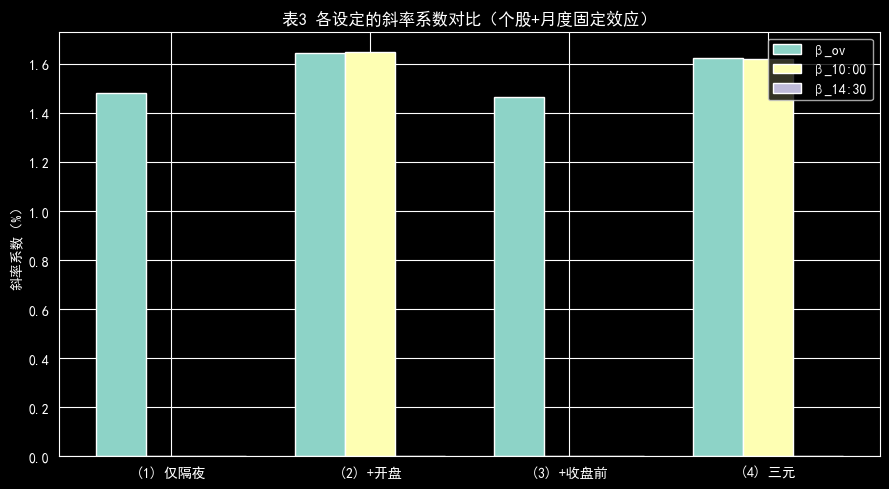

In [12]:
# 将隔夜的收益率纳入到回归当中（table3，三元回归与双元回归对比图表，见下表与图）
table3_specs = [
    ("r_ov",),
    ("r_ov", "r_10_00"),
    ("r_ov", "r_14_30"),
    ("r_ov", "r_10_00", "r_14_30"),
]
table3_results = fit_fe_specs(halfhour_panel, "r_last", table3_specs, fe_cols=("ts_code", "ym"))
table3 = format_fe_table(
    table3_results, ["(1)", "(2)", "(3)", "(4)"], var_order=("r_ov", "r_10_00", "r_14_30")
)
print("表3 隔夜动量 vs 开盘动量（个股+月度固定效应，百分比口径）：")
display(table3)
table3.to_csv(OUTPUT_DIR / "table3_overnight_vs_opening_fe.csv", encoding="gbk")

print("论文Table 3参考值：β_ov = 2.881 / 2.922 / 2.780 / 2.812；β_10:00 = 空缺 / 0.641 / 空缺 / 0.566；")
print("                 β_14:30 = 空缺 / 空缺 / 6.021 / 6.012；R-squared = 0.22 / 0.23 / 0.57 / 0.58（%）")
# ------------------------------ 三元 vs 双元回归系数对比图
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.sans-serif'] = ['SimHei']
mpl.rcParams['axes.unicode_minus'] = False

chart_vars = [("r_ov", "β_ov"), ("r_10_00", "β_10:00"), ("r_14:30", "β_14:30")]
chart_data = {
    label: [
        res["params"].get(var, np.nan) * 100 for res in table3_results
    ]
    for var, label in chart_vars
}
fig, ax = plt.subplots(figsize=(9, 5))
x_pos = np.arange(len(table3_results))
width = 0.25
for k, (label, values) in enumerate(chart_data.items()):
    vals = [0 if np.isnan(v) else v for v in values]
    ax.bar(x_pos + (k - 1) * width, vals, width, label=label)
ax.set_xticks(x_pos)
ax.set_xticklabels(["(1) 仅隔夜", "(2) +开盘", "(3) +收盘前", "(4) 三元"])
ax.set_ylabel('斜率系数（%）')
ax.set_title('表3 各设定的斜率系数对比（个股+月度固定效应）')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'table3_coefficients.png', dpi=120)
plt.show()


### 1.5 隔夜收益 vs 不同开盘时间点收益

用连续竞价阶段前 5、10、15、20、25、30 分钟的价格变动重新定义开盘动量（r_9:35 … r_10:00），每个替代口径分别与隔夜成分、倒数半小时收益一起回归（主口径：个股+月度固定效应）。
论文发现：替代开盘动量的系数符号随口径由负转正（连续竞价的价格信号混杂了信息消化与流动性供给），而隔夜成分系数稳定为正——隔夜收益（盘前集合竞价）才是尾盘动量的主要来源。

**本样本复现结果**：隔夜系数在各设定下稳定（β_ov ≈ 1.60–1.65），与论文的稳定性特征一致；但六个替代开盘口径系数全部显著为正（r_9:35 最强，达 2.45），未复现论文“前5-10分钟为负、随后转正”的符号翻转——本样本中开盘后任意时点的价格变动对尾盘均为正向预测，混合信号特征不明显。


In [13]:
# 对不同时间点的开盘收益，与隔夜收益，与倒数第二个半小时收益分别进行三元回归。（对应table4）
table4_alt_vars = ["r_open_935", "r_open_940", "r_open_945", "r_open_950", "r_open_955", "r_10_00"]
table4_specs = [("r_ov", alt, "r_14_30") for alt in table4_alt_vars]
table4_results = fit_fe_specs(halfhour_panel, "r_last", table4_specs, fe_cols=("ts_code", "ym"))
table4 = format_fe_table(
    table4_results,
    ["({})".format(i + 1) for i in range(len(table4_specs))],
    var_order=("r_ov", *table4_alt_vars, "r_14_30"),
)
print("表4 隔夜收益 vs 替代开盘收益（个股+月度固定效应，百分比口径）：")
display(table4)
table4.to_csv(OUTPUT_DIR / "table4_alternative_opening_fe.csv", encoding="gbk")

print("论文Table 4参考值：β_ov ≈ 2.78-2.81；β_9:35 = -0.077*、β_9:40 = -0.058*、β_9:45 = 0.300***、")
print("                 β_9:50 = 0.421***、β_9:55 = 0.387***、β_10:00 = 0.566***；β_14:30 ≈ 6.02；R-squared = 0.57-0.58（%）")


表4 隔夜收益 vs 替代开盘收益（个股+月度固定效应，百分比口径）：


,(1),(2),(3),(4),(5),(6)
"r_ov,t",1.645***,1.595***,1.598***,1.604***,1.617***,1.624***
,(0.0179),(0.0179),(0.0179),(0.0179),(0.0179),(0.0179)
"r_9:35,t",2.451***,,,,,
,(0.0252),,,,,
"r_9:40,t",,1.625***,,,,
,,(0.0213),,,,
"r_9:45,t",,,1.491***,,,
,,,(0.0192),,,
"r_9:50,t",,,,1.579***,,
,,,,(0.0180),,


论文Table 4参考值：β_ov ≈ 2.78-2.81；β_9:35 = -0.077*、β_9:40 = -0.058*、β_9:45 = 0.300***、
                 β_9:50 = 0.421***、β_9:55 = 0.387***、β_10:00 = 0.566***；β_14:30 ≈ 6.02；R-squared = 0.57-0.58（%）


### 1.6 日内收益跳跃与尾盘动量（对应论文5节）

论文以日内价格跳跃作为个股层面信息冲击的代理变量，检验跳跃日后尾盘动量的动态变化。
核心假说：正跳跃日（好消息）后信息不确定性下降，尾盘动量减弱；负跳跃日（坏消息）后信息消化更慢，尾盘动量增强（Hong et al. 2000 的“坏消息传播慢”在日内时序层面的体现）。

全样本的分组差异检验见研究分支 #1.6.4。


#### 1.6.1 日内跳跃检测与跳跃日统计（复现table5）

In [14]:
# 按照论文附录A.2（Andersen et al. 2012 的 MedRV 比率检验 + 递归日内跳跃识别）检测每股每日跳跃：
#   1) 5分钟对数收益：每日48个区间，价格网格为 9:30开盘价 与 9:35,…,11:30,13:05,…,15:00 收盘价
#      （原文未写死的两个口径，已确认：首区间 9:30开盘价→9:35收盘价 纳入检测，即隔夜跳空可被判为跳跃；
#       午间跨段 11:30→13:05 纳入为一个区间；价格网格不完整或含非正价格的交易日不做检测，按无跳跃处理）；
#   2) 计算 RV、MedRV、MedRQ 与比率统计量 Z，显著性水平 α = 0.01%（临界值 Φ^{-1}(0.9999) ≈ 3.719）；
#   3) 显著日进入递归识别：逐个用当日收益中位数替换各区间的收益，使 Z 降幅最大的区间记为跳跃，
#      替换该区间收益并重复，直至 Z 不再显著；过滤幅度小于两倍最小报价单位（0.02元）的伪跳跃；
#   4) 当日累计跳跃收益为正（负）记为正（负）跳跃日，对应论文 PJ/NJ 日。
# 检测范围为股票池个股的全部分钟可得交易日（含入池前一年），保证“前一交易日”虚拟变量不缺。
# 全量构建耗时较长，结果缓存至 output_data/stock_jump_days_v1.parquet。

from scipy.stats import norm

JUMP_CACHE = OUTPUT_DIR / "stock_jump_days_v1.parquet"
_JUMP_ALPHA = 0.0001                      # 论文附录A.2：显著性水平 0.01%
_JUMP_Z_CRIT = float(norm.ppf(1 - _JUMP_ALPHA))
_JUMP_TICK = 0.02                         # 两倍最小报价单位（0.01元 × 2）
_MU1 = np.sqrt(2.0 / np.pi)
_Z_DENOM_CONST = _MU1 ** -4 + 2 * _MU1 ** -2 - 5
_C1 = np.pi / (6 - 4 * np.sqrt(3) + np.pi)  # MedRV 常数


def _jump_grid_stamps():
    """每日48个5分钟收盘价时刻（9:35..11:30、13:05..15:00）。"""
    stamps = []
    for session_start in ("09:35", "13:05"):
        t = pd.Timestamp("2000-01-01 " + session_start)
        end = pd.Timestamp("2000-01-01 " + ("11:30" if session_start == "09:35" else "15:00"))
        while t <= end:
            stamps.append(t.strftime("%H:%M:%S"))
            t += pd.Timedelta(minutes=5)
    return stamps


_JUMP_GRID = _jump_grid_stamps()
_M = len(_JUMP_GRID)  # 48


def _z_stat_from_sums(rv, s2, s4, m=_M):
    """由 RV、med3 平方和、四次方和计算比率统计量 Z。"""
    medrv = _C1 * (m / (m - 2)) * s2
    c2 = 3 * np.pi * m / (9 * np.pi + 72 - 52 * np.sqrt(3))
    medrq = c2 * (m / (m - 2)) * s4
    with np.errstate(divide="ignore", invalid="ignore"):
        denom = np.sqrt(_Z_DENOM_CONST * np.maximum(1.0, medrq / np.square(medrv)))
        return np.sqrt(m) * (rv - medrv) / rv / denom


def _z_stats_vectorized(logret):
    """第一阶段（向量化）：对 day×48 的对数收益矩阵计算 Z。"""
    m = logret.shape[1]
    rv = np.square(logret).sum(axis=1)
    a0 = np.abs(logret[:, 2:])
    a1 = np.abs(logret[:, 1:-1])
    a2 = np.abs(logret[:, :-2])
    med3 = np.median(np.stack([a0, a1, a2], axis=2), axis=2)
    s2 = np.square(med3).sum(axis=1)
    s4 = np.square(np.square(med3)).sum(axis=1)
    return _z_stat_from_sums(rv, s2, s4, m)


def _detect_day_jumps(r, prices):
    """第二阶段（递归）：对单日识别全部跳跃区间，返回跳跃收益列表（已过滤伪跳跃）。"""
    m = len(r)
    r = r.copy()
    day_median = float(np.median(r))
    absr = np.abs(r)
    med3 = np.median(
        np.stack([absr[2:], absr[1:-1], absr[:-2]], axis=1), axis=1
    )  # med3[k-2] = med(|r_k|,|r_{k-1}|,|r_{k-2}|), k=2..m-1
    rv = float(np.square(r).sum())
    s2 = float(np.square(med3).sum())
    s4 = float(np.power(med3, 4).sum())
    z = _z_stat_from_sums(rv, s2, s4, m)
    jumps = []
    while z > _JUMP_Z_CRIT and len(jumps) < m - 2:
        # 逐个尝试把第 j 个区间替换为当日中位数，增量更新 RV/S2/S4，取使 Z 降幅最大的 j
        best_gain, best_j = -np.inf, -1
        for j in range(m):
            delta_r2 = day_median ** 2 - r[j] ** 2
            gain_rv = rv + delta_r2
            if gain_rv <= 0:
                continue
            # 受影响的 med3 下标：k ∈ {j, j+1, j+2} ∩ [2, m-1]，对应 med3 下标 k-2
            s2_new, s4_new = s2, s4
            for k in (j, j + 1, j + 2):
                if k < 2 or k > m - 1:
                    continue
                vals = [absr[k], absr[k - 1], absr[k - 2]]
                if k == j:
                    vals[0] = day_median
                elif k - 1 == j:
                    vals[1] = day_median
                else:
                    vals[2] = day_median
                new_med = float(np.median(vals))
                s2_new += new_med ** 2 - med3[k - 2] ** 2
                s4_new += new_med ** 4 - med3[k - 2] ** 4
            z_j = _z_stat_from_sums(gain_rv, s2_new, s4_new, m)
            if z - z_j > best_gain:
                best_gain, best_j = z - z_j, j
        if best_j < 0:
            break
        r_jump = float(r[best_j])
        price_before = float(prices[best_j])
        # 用中位数替换后重新计算基准量
        absr[best_j] = day_median
        r[best_j] = day_median
        rv = rv - r_jump ** 2 + day_median ** 2
        for k in (best_j, best_j + 1, best_j + 2):
            if k < 2 or k > m - 1:
                continue
            med3[k - 2] = float(np.median([absr[k], absr[k - 1], absr[k - 2]]))
        s2 = float(np.square(med3).sum())
        s4 = float(np.power(med3, 4).sum())
        z = _z_stat_from_sums(rv, s2, s4, m)
        if abs(r_jump) * price_before >= _JUMP_TICK:
            jumps.append(r_jump)
    return jumps


def _extract_daily_5min_prices(path):
    """从年度分钟CSV提取每日5分钟价格网格（9:30开盘价 + 48个5分钟收盘价）。"""
    table = pv.read_csv(
        path,
        read_options=pv.ReadOptions(encoding="utf-8-sig"),
        convert_options=pv.ConvertOptions(
            include_columns=["时间", "开盘价", "收盘价"],
            column_types={"时间": "string", "开盘价": "float64", "收盘价": "float64"},
        ),
    )
    frame = table.to_pandas()
    day = frame["时间"].str.slice(0, 10)
    hm = frame["时间"].str.slice(11)
    open_930 = pd.Series(
        frame.loc[hm == "09:30:00", "开盘价"].to_numpy(),
        index=day.loc[hm == "09:30:00"],
    )
    frame = frame.loc[hm.isin(_JUMP_GRID)].copy()
    frame["hm"] = hm.loc[frame.index]
    frame["trade_date"] = day.loc[frame.index]
    wide = frame.pivot_table(index="trade_date", columns="hm", values="收盘价", aggfunc="last")
    wide = wide.reindex(columns=_JUMP_GRID)
    wide.insert(0, "open", open_930)
    return wide


def build_jump_day_panel(stock_pool, cache=JUMP_CACHE):
    """按股票遍历本地分钟文件，检测逐日跳跃并输出跳跃日面板（流式写入缓存）。"""
    if cache.exists():
        return pd.read_parquet(cache)

    pool_by_stock = stock_pool.groupby("ts_code")["trade_date"].agg(["min", "max"])
    temp_cache = cache.with_name(cache.stem + ".tmp.parquet")
    if temp_cache.exists():
        temp_cache.unlink()
    writer = None
    batch = []
    total = len(pool_by_stock)
    try:
        for number, (code, row) in enumerate(pool_by_stock.iterrows(), start=1):
            frames = []
            for year in range(row["min"].year - 1, row["max"].year + 1):
                path = minute_file(code, year)
                if path.exists():
                    frames.append(_extract_daily_5min_prices(path))
            if frames:
                prices = pd.concat(frames).sort_index()
                prices = prices[~prices.index.duplicated(keep="last")]
                close_1500 = prices["15:00:00"]
                ret_cc = (close_1500 / close_1500.shift(1) - 1).astype("float32")
                valid = prices.notna().all(axis=1) & (prices > 0).all(axis=1)
                price_mat = prices.loc[valid].to_numpy(dtype="float64")
                logret = np.diff(np.log(price_mat), axis=1)
                z_all = _z_stats_vectorized(logret)
                cum_jump = np.zeros(len(prices), dtype="float64")
                n_jumps = np.zeros(len(prices), dtype="int32")
                valid_pos = np.flatnonzero(valid.to_numpy())
                for row_no in np.flatnonzero(z_all > _JUMP_Z_CRIT):
                    jumps = _detect_day_jumps(logret[row_no], price_mat[row_no, :-1])
                    day_idx = valid_pos[row_no]
                    n_jumps[day_idx] = len(jumps)
                    cum_jump[day_idx] = float(np.sum(jumps)) if jumps else 0.0
                one = pd.DataFrame({
                    "ts_code": code,
                    "trade_date": pd.to_datetime(prices.index),
                    "ret_cc": ret_cc.to_numpy(),
                    "cum_jump_ret": cum_jump.astype("float32"),
                    "n_jumps": n_jumps.astype("int16"),
                    "pj_day": (n_jumps > 0) & (cum_jump > 0),
                    "nj_day": (n_jumps > 0) & (cum_jump < 0),
                })
                batch.append(one)
            if number % 500 == 0 or number == total:
                if batch:
                    chunk = pd.concat(batch, ignore_index=True)
                    batch = []
                    table = pa.Table.from_pandas(chunk, preserve_index=False)
                    if writer is None:
                        writer = pq.ParquetWriter(temp_cache, table.schema, compression="zstd")
                    writer.write_table(table)
                print("跳跃日检测进度：{}/{}".format(number, total))
    finally:
        if writer is not None:
            writer.close()
    temp_cache.replace(cache)
    return pd.read_parquet(cache)


jump_daily = build_jump_day_panel(stock_pool_daily)

# ------------------------------ 复现论文 Table 5：跳跃日统计（样本日与回归一致）
jump_on_sample = halfhour_panel[["ts_code", "trade_date"]].merge(
    jump_daily, on=["ts_code", "trade_date"], how="left"
)
n_sample = len(jump_on_sample)
retpj = jump_on_sample.loc[jump_on_sample["pj_day"].fillna(False), "cum_jump_ret"] * 100
retnj = jump_on_sample.loc[jump_on_sample["nj_day"].fillna(False), "cum_jump_ret"] * 100
# RET（日度收盘收益）原始序列含复牌跳空与坏点（如2006年初的哨兵价格），
# 与1.1.3.3节一致按 |ret_cc| ≤ 21% 过滤不可能波动后再统计。
ret_all = jump_on_sample.loc[jump_on_sample["ret_cc"].abs() <= 0.21, "ret_cc"].dropna() * 100

table5 = pd.DataFrame({
    "Mean": [retpj.mean(), retnj.mean(), ret_all.mean()],
    "Std.": [retpj.std(), retnj.std(), ret_all.std()],
    "5%": [retpj.quantile(0.05), retnj.quantile(0.05), ret_all.quantile(0.05)],
    "25%": [retpj.quantile(0.25), retnj.quantile(0.25), ret_all.quantile(0.25)],
    "50%": [retpj.quantile(0.50), retnj.quantile(0.50), ret_all.quantile(0.50)],
    "75%": [retpj.quantile(0.75), retnj.quantile(0.75), ret_all.quantile(0.75)],
    "95%": [retpj.quantile(0.95), retnj.quantile(0.95), ret_all.quantile(0.95)],
    "Ratio": [len(retpj) / n_sample, len(retnj) / n_sample, np.nan],
}, index=["RETPJ", "RETNJ", "RET"]).round(4)
print("表5 跳跃日累计跳跃收益与日收益统计（%，Ratio为跳跃日占比）：")
display(table5)
table5.to_csv(OUTPUT_DIR / "table5_jump_day_summary.csv", encoding="gbk")
print("论文Table 5参考值：RETPJ均值 2.133、占比14.09%；RETNJ均值 -2.094、占比10.73%；RET均值 0.044")


表5 跳跃日累计跳跃收益与日收益统计（%，Ratio为跳跃日占比）：


,Mean,Std.,5%,25%,50%,75%,95%,Ratio
RETPJ,2.3874,1.6383,0.7470,1.3077,1.9450,2.9638,5.5742,0.0354
RETNJ,-2.0875,1.4249,-4.7741,-2.5388,-1.7252,-1.1935,-0.6780,0.0208
RET,0.0278,2.9758,-4.4257,-1.4069,0.0000,1.3100,4.8621,NaN


论文Table 5参考值：RETPJ均值 2.133、占比14.09%；RETNJ均值 -2.094、占比10.73%；RET均值 0.044


#### 1.6.2 日内动量与跳跃方向的交互回归（复现table6）

**本样本复现结果**：交互项符号与论文相反——隔夜口径下 PJ×r_ov 弱正（+0.20）、NJ×r_ov 显著为负（-1.33），论文则分别为 -2.18 与 +2.40；首半小时口径下两个交互项均为负。即论文“正跳跃日后动量减弱、负跳跃日后增强”的不对称性在本样本中不成立。跳跃日占比也明显更低（3.5% / 2.1%，论文 14.1% / 10.7%），主要源于样本构成：我们的股票池以大盘非ST股为主，且α=0.01%的检验对大盘低波动股更难触发。


In [15]:
# 区分跳跃方向（前一交易日正/负跳跃日）进行回归分析
jump_lag = jump_daily.sort_values(["ts_code", "trade_date"]).copy()
jump_lag[["PJ", "NJ"]] = jump_lag.groupby("ts_code")[["pj_day", "nj_day"]].shift(1)
panel_jump = halfhour_panel.merge(
    jump_lag[["ts_code", "trade_date", "PJ", "NJ"]],
    on=["ts_code", "trade_date"], how="left",
)
panel_jump[["PJ", "NJ"]] = panel_jump[["PJ", "NJ"]].fillna(False)

# 交互项（PJ/NJ 为0时交互项为0，不产生缺失，样本量与表1一致）
panel_jump["pj_x_r_ov"] = panel_jump["PJ"] * panel_jump["r_ov"]
panel_jump["nj_x_r_ov"] = panel_jump["NJ"] * panel_jump["r_ov"]
panel_jump["pj_x_r_1st"] = panel_jump["PJ"] * panel_jump["r_1st"]
panel_jump["nj_x_r_1st"] = panel_jump["NJ"] * panel_jump["r_1st"]

t6_specs_ov = [("r_ov", "pj_x_r_ov", "nj_x_r_ov"), ("r_ov", "pj_x_r_ov", "nj_x_r_ov", "r_14_30")]
t6_specs_1st = [("r_1st", "pj_x_r_1st", "nj_x_r_1st"), ("r_1st", "pj_x_r_1st", "nj_x_r_1st", "r_14_30")]
t6_results = (
    fit_fe_specs(panel_jump, "r_last", t6_specs_ov, fe_cols=("ts_code", "ym"))
    + fit_fe_specs(panel_jump, "r_last", t6_specs_1st, fe_cols=("ts_code", "ym"))
)
table6 = format_fe_table(
    t6_results,
    ["隔夜(1)", "隔夜(2)", "首半小时(1)", "首半小时(2)"],
    var_order=("r_1st", "r_ov", "pj_x_r_1st", "pj_x_r_ov", "nj_x_r_1st", "nj_x_r_ov", "r_14_30"),
)
print("表6 尾盘动量与价格跳跃（个股+月度固定效应，百分比口径）：")
display(table6)
table6.to_csv(OUTPUT_DIR / "table6_jump_interaction_fe.csv", encoding="gbk")

print("论文Table 6参考值（隔夜(2) / 首半小时(2)）：")
print("  β_r = 2.781 / 1.722；PJ×r = -2.182 / -1.621；NJ×r = 2.401 / 2.522；β_14:30 = 5.973 / 5.971")
print("  即：正跳跃日后尾盘动量减弱，负跳跃日后增强（不对称性）。")


表6 尾盘动量与价格跳跃（个股+月度固定效应，百分比口径）：


,隔夜(1),隔夜(2),首半小时(1),首半小时(2)
"r_1st,t",,,1.677***,1.652***
,,,(0.0130),(0.0130)
"r_ov,t",1.502***,1.484***,,
,(0.0184),(0.0183),,
"PJ×r_1st,t",,,-0.535***,-0.523***
,,,(0.0618),(0.0617)
"PJ×r_ov,t",0.205**,0.204**,,
,(0.0898),(0.0897),,
"NJ×r_1st,t",,,-0.670***,-0.660***
,,,(0.0868),(0.0867)


论文Table 6参考值（隔夜(2) / 首半小时(2)）：
  β_r = 2.781 / 1.722；PJ×r = -2.182 / -1.621；NJ×r = 2.401 / 2.522；β_14:30 = 5.973 / 5.971
  即：正跳跃日后尾盘动量减弱，负跳跃日后增强（不对称性）。


#### 1.6.3 跳跃后效应的事件窗口稳健性（复现table7）

**本样本复现结果**：隔夜口径的 PJ 交互效应随窗口拉长由弱正转负（1日 +0.20 → 3日 -0.17），衰减方向与论文一致，但符号起点不同；NJ 交互效应始终为负且衰减不单调。整体上论文“交互效应随事件窗口单调衰减”的规律在本样本中只部分成立。


In [16]:
# 复现论文Table 7：1/2/3日事件窗口的跳跃后效应（均控制 r_14:30，个股+月度固定效应）。
jump_win = jump_daily.sort_values(["ts_code", "trade_date"]).copy()
_grp = jump_win.groupby("ts_code")
pj_shifts = {i: _grp["pj_day"].shift(i) for i in (1, 2, 3)}
nj_shifts = {i: _grp["nj_day"].shift(i) for i in (1, 2, 3)}
for k in (1, 2, 3):
    jump_win["PJ_w{}".format(k)] = pd.concat([pj_shifts[i] for i in range(1, k + 1)], axis=1).max(axis=1)
    jump_win["NJ_w{}".format(k)] = pd.concat([nj_shifts[i] for i in range(1, k + 1)], axis=1).max(axis=1)

panel_win = halfhour_panel.merge(
    jump_win[["ts_code", "trade_date", "PJ_w1", "NJ_w1", "PJ_w2", "NJ_w2", "PJ_w3", "NJ_w3"]],
    on=["ts_code", "trade_date"], how="left",
)
win_cols = ["PJ_w1", "NJ_w1", "PJ_w2", "NJ_w2", "PJ_w3", "NJ_w3"]
panel_win[win_cols] = panel_win[win_cols].fillna(0.0)

t7_results = []
for base_var in ("r_ov", "r_1st"):
    for k in (1, 2, 3):
        sub = panel_win[["r_last", base_var, "r_14_30", "ts_code", "ym",
                         "PJ_w{}".format(k), "NJ_w{}".format(k)]].copy()
        sub["pj_x_r"] = sub["PJ_w{}".format(k)] * sub[base_var]
        sub["nj_x_r"] = sub["NJ_w{}".format(k)] * sub[base_var]
        t7_results += fit_fe_specs(
            sub, "r_last", [(base_var, "pj_x_r", "nj_x_r", "r_14_30")], fe_cols=("ts_code", "ym")
        )

_t7_var_labels = {"pj_x_r": "PJ×r,t", "nj_x_r": "NJ×r,t"}
_FE_VAR_LABELS.update(_t7_var_labels)
table7 = format_fe_table(
    t7_results,
    ["隔夜-1日", "隔夜-2日", "隔夜-3日", "首半小时-1日", "首半小时-2日", "首半小时-3日"],
    var_order=("r_1st", "r_ov", "pj_x_r", "nj_x_r", "r_14_30"),
)
print("表7 跳跃后效应的事件窗口稳健性（个股+月度固定效应，百分比口径）：")
display(table7)
table7.to_csv(OUTPUT_DIR / "table7_post_jump_windows_fe.csv", encoding="gbk")

print("论文Table 7参考值（隔夜 1日/2日/3日）：PJ×r_ov = -2.18 / -0.99 / -0.59；NJ×r_ov = 2.40 / 2.09 / 1.86；")
print("  （首半小时 1日/2日/3日）：PJ×r_1st = -1.62 / -1.09 / -0.66；NJ×r_1st = 2.52 / 2.08 / 1.87——交互效应随窗口衰减。")


表7 跳跃后效应的事件窗口稳健性（个股+月度固定效应，百分比口径）：


,隔夜-1日,隔夜-2日,隔夜-3日,首半小时-1日,首半小时-2日,首半小时-3日
"r_1st,t",,,,1.652***,1.694***,1.716***
,,,,(0.0130),(0.0134),(0.0138)
"r_ov,t",1.484***,1.505***,1.541***,,,
,(0.0183),(0.0189),(0.0194),,,
"PJ×r,t",0.204**,-0.049,-0.172***,-0.523***,-0.652***,-0.514***
,(0.0897),(0.0663),(0.0557),(0.0617),(0.0459),(0.0389)
"NJ×r,t",-1.332***,-0.966***,-1.041***,-0.660***,-0.615***,-0.660***
,(0.1235),(0.0924),(0.0776),(0.0867),(0.0636),(0.0531)
"r_14:30,t",4.215***,4.214***,4.214***,4.159***,4.158***,4.157***
,(0.0377),(0.0377),(0.0377),(0.0377),(0.0377),(0.0377)


论文Table 7参考值（隔夜 1日/2日/3日）：PJ×r_ov = -2.18 / -0.99 / -0.59；NJ×r_ov = 2.40 / 2.09 / 1.86；
  （首半小时 1日/2日/3日）：PJ×r_1st = -1.62 / -1.09 / -0.66；NJ×r_1st = 2.52 / 2.08 / 1.87——交互效应随窗口衰减。


#### #1.6.4 全样本分组检验：跳跃后效应是否因市值/ST/板块而异（研究分支）

1.6.2节的交互回归在主股票池（大盘非ST）中未能复现论文的不对称性（PJ×r 为负、NJ×r 为正）。
一个自然的猜想是：论文机制（坏消息传播慢、卖空约束）主要作用于小市值与ST股，而主池恰好将其剔除。
本分支用1.1.3节的论文口径全样本（不限市值、含ST）重做表6交互回归，按 **大盘非ST / 小市值非ST / ST股 / 其他** 与 **主板 / 中小企业板 / 创业板** 分组，对比各组 PJ×r、NJ×r 的符号与量级，检验该猜想是否成立。

**本样本复现结果**：猜想**部分得到印证**——论文式的不对称性只在 ST 股组显现且仅负跳跃一侧：ST 股组 NJ×r_ov = +2.16（论文 +2.40），负跳跃日后隔夜动量确实增强；但 PJ×r 在各组均非负（论文为显著负值），且大盘非ST、小市值、主板、中小板、创业板各组的 NJ×r 均为负。D 其他组（早期市值缺失股）两个交互项同为正，但该组样本小、拟合差，仅供参考。
总体结论：论文“正跳跃减弱、负跳跃增强”的完整不对称机制在 A 股全样本中不稳健，只有“负跳跃日后隔夜动量增强”在 ST 股中得到支持；大盘股中负跳跃反而伴随隔夜动量减弱。


In [17]:
# 论文池收益率面板 v2：在1.1.3.2节基础上新增 9:30 开盘价锚点（提供 r_ov），
# 收益率定义与1.1.1节 v2 面板一致；ST/*ST 仍由分钟文件“名称”列逐日识别（覆盖全样本期）。
# 为控制体积仅保留本节所需变量（r_1st / r_ov / r_14_30 / r_last / is_st）。
# 全量构建耗时较长，结果缓存至 output_data/stock_halfhour_returns_paper_pool_v2.parquet。

PAPER_RETURN_CACHE_V2 = OUTPUT_DIR / "stock_halfhour_returns_paper_pool_v2.parquet"


def _extract_daily_anchor_close_with_name_v2(path):
    """从年度分钟CSV提取每日锚点价格（v2口径）与当日名称（用于识别ST）。"""
    table = pv.read_csv(
        path,
        read_options=pv.ReadOptions(encoding="utf-8-sig"),
        convert_options=pv.ConvertOptions(
            include_columns=["时间", "开盘价", "收盘价", "名称"],
            column_types={"时间": "string", "开盘价": "float64", "收盘价": "float64", "名称": "string"},
        ),
    )
    frame = table.to_pandas()
    day = frame["时间"].str.slice(0, 10)
    hm = frame["时间"].str.slice(11)
    day_name = frame.dropna(subset=["名称"]).groupby(day)["名称"].first()
    open_930 = pd.Series(
        frame.loc[hm == "09:30:00", "开盘价"].to_numpy(),
        index=day.loc[hm == "09:30:00"],
    )
    frame = frame.loc[hm.isin(_ANCHOR_TIMES)].copy()
    frame["hm"] = hm.loc[frame.index]
    frame["trade_date"] = day.loc[frame.index]
    wide = frame.pivot_table(index="trade_date", columns="hm", values="收盘价", aggfunc="last")
    wide["open_0930"] = open_930
    wide["name"] = day_name
    return wide


def build_paper_return_panel_v2(stock_pool, cache=PAPER_RETURN_CACHE_V2):
    """按股票遍历本地分钟文件，构建论文池 v2 日度收益率面板（含 r_ov 与逐日ST标记，流式写入）。"""
    if cache.exists():
        return pd.read_parquet(cache)

    pool_by_stock = stock_pool.groupby("ts_code")["trade_date"].agg(["min", "max", set])
    temp_cache = cache.with_name(cache.stem + ".tmp.parquet")
    if temp_cache.exists():
        temp_cache.unlink()
    writer = None
    batch = []
    total = len(pool_by_stock)
    try:
        for number, (code, row) in enumerate(pool_by_stock.iterrows(), start=1):
            frames = []
            for year in range(row["min"].year - 1, row["max"].year + 1):
                path = minute_file(code, year)
                if path.exists():
                    frames.append(_extract_daily_anchor_close_with_name_v2(path))
            if frames:
                wide = pd.concat(frames).sort_index()
                wide = wide[~wide.index.duplicated(keep="last")]
                prev_close = wide["15:00:00"].shift(1)
                one = pd.DataFrame({
                    "ts_code": code,
                    "trade_date": pd.to_datetime(wide.index),
                    "r_1st": (wide["10:00:00"] / prev_close - 1).astype("float32"),
                    "r_ov": (wide["open_0930"] / prev_close - 1).astype("float32"),
                    "r_14_30": (wide["14:30:00"] / wide["14:00:00"] - 1).astype("float32"),
                    "r_last": (wide["15:00:00"] / wide["14:30:00"] - 1).astype("float32"),
                    "is_st": np.asarray(
                        wide["name"].astype("string").str.upper().str.contains("ST", regex=False, na=False),
                        dtype=bool,
                    ),
                })
                one = one.loc[one["trade_date"].isin(row["set"])]
                one = one.replace([np.inf, -np.inf], np.nan).dropna()
                if not one.empty:
                    batch.append(one)
            if number % 500 == 0 or number == total:
                if batch:
                    chunk = pd.concat(batch, ignore_index=True)
                    batch = []
                    table = pa.Table.from_pandas(chunk, preserve_index=False)
                    if writer is None:
                        writer = pq.ParquetWriter(temp_cache, table.schema, compression="zstd")
                    writer.write_table(table)
                print("论文池 v2 收益率面板构建进度：{}/{}".format(number, total))
    finally:
        if writer is not None:
            writer.close()
    temp_cache.replace(cache)
    return pd.read_parquet(cache)


paper_panel_v2 = build_paper_return_panel_v2(paper_stock_pool)

paper_panel_v2_summary = pd.DataFrame({
    "股票数": [paper_panel_v2["ts_code"].nunique()],
    "股票-交易日数": [len(paper_panel_v2)],
    "ST股-交易日数": [int(paper_panel_v2["is_st"].sum())],
    "首个交易日": [paper_panel_v2["trade_date"].min()],
    "最后交易日": [paper_panel_v2["trade_date"].max()],
}, index=["论文池v2收益率面板"])
display(paper_panel_v2_summary)


,股票数,股票-交易日数,ST股-交易日数,首个交易日,最后交易日
论文池v2收益率面板,5108,13912541,569427,2001-01-09,2025-12-15


In [18]:
# 把跳跃日检测扩展到论文口径股票池：主池个股的检测结果直接复用1.6.1节缓存，
# 仅对论文池独有的个股（从未进入主池的小市值/ST股）补做检测，合并后缓存至
# output_data/stock_jump_days_paper_v1.parquet。

PAPER_JUMP_CACHE = OUTPUT_DIR / "stock_jump_days_paper_v1.parquet"


def build_paper_jump_daily(paper_pool, cache=PAPER_JUMP_CACHE):
    """构建论文口径股票池的跳跃日面板（主池个股复用缓存，仅补检测新增个股）。"""
    if cache.exists():
        return pd.read_parquet(cache)

    main_jump = pd.read_parquet(OUTPUT_DIR / "stock_jump_days_v1.parquet")
    covered = set(main_jump["ts_code"].unique())
    extra_pool = paper_pool.loc[~paper_pool["ts_code"].isin(covered)]
    pool_by_stock = extra_pool.groupby("ts_code")["trade_date"].agg(["min", "max"])
    print("主池缓存复用 {:,} 行；需补检测的新增个股：{} 只。".format(len(main_jump), len(pool_by_stock)))

    temp_cache = cache.with_name(cache.stem + ".tmp.parquet")
    if temp_cache.exists():
        temp_cache.unlink()
    writer = None
    batch = []
    total = len(pool_by_stock)
    try:
        for number, (code, row) in enumerate(pool_by_stock.iterrows(), start=1):
            frames = []
            for year in range(row["min"].year - 1, row["max"].year + 1):
                path = minute_file(code, year)
                if path.exists():
                    frames.append(_extract_daily_5min_prices(path))
            if frames:
                prices = pd.concat(frames).sort_index()
                prices = prices[~prices.index.duplicated(keep="last")]
                close_1500 = prices["15:00:00"]
                ret_cc = (close_1500 / close_1500.shift(1) - 1).astype("float32")
                valid = prices.notna().all(axis=1) & (prices > 0).all(axis=1)
                price_mat = prices.loc[valid].to_numpy(dtype="float64")
                logret = np.diff(np.log(price_mat), axis=1)
                z_all = _z_stats_vectorized(logret)
                cum_jump = np.zeros(len(prices), dtype="float64")
                n_jumps = np.zeros(len(prices), dtype="int32")
                valid_pos = np.flatnonzero(valid.to_numpy())
                for row_no in np.flatnonzero(z_all > _JUMP_Z_CRIT):
                    jumps = _detect_day_jumps(logret[row_no], price_mat[row_no, :-1])
                    day_idx = valid_pos[row_no]
                    n_jumps[day_idx] = len(jumps)
                    cum_jump[day_idx] = float(np.sum(jumps)) if jumps else 0.0
                batch.append(pd.DataFrame({
                    "ts_code": code,
                    "trade_date": pd.to_datetime(prices.index),
                    "ret_cc": ret_cc.to_numpy(),
                    "cum_jump_ret": cum_jump.astype("float32"),
                    "n_jumps": n_jumps.astype("int16"),
                    "pj_day": (n_jumps > 0) & (cum_jump > 0),
                    "nj_day": (n_jumps > 0) & (cum_jump < 0),
                }))
            if number % 200 == 0 or number == total:
                if batch:
                    chunk = pd.concat(batch, ignore_index=True)
                    batch = []
                    table = pa.Table.from_pandas(chunk, preserve_index=False)
                    if writer is None:
                        writer = pq.ParquetWriter(temp_cache, table.schema, compression="zstd")
                    writer.write_table(table)
                print("论文池新增个股跳跃检测进度：{}/{}".format(number, total))
    finally:
        if writer is not None:
            writer.close()

    frames = [main_jump]
    if temp_cache.exists():
        frames.append(pd.read_parquet(temp_cache))
        temp_cache.unlink()
    combined = pd.concat(frames, ignore_index=True)
    combined = combined.sort_values(["ts_code", "trade_date"], ignore_index=True)
    combined.to_parquet(cache, index=False, compression="zstd")
    return combined


paper_jump_daily = build_paper_jump_daily(paper_stock_pool)
print("论文池跳跃日面板：{:,} 行，{} 只股票。".format(len(paper_jump_daily), paper_jump_daily["ts_code"].nunique()))


论文池跳跃日面板：11,920,972 行，5112 只股票。


In [19]:
# 全样本分组交互回归：数据清洗口径与1.1.3.3节一致（连续交易日 + 半小时收益不可能波动 + |r_1st|/|r_ov| ≤ 30%）。
paper_panel_v2 = paper_panel_v2.sort_values(["ts_code", "trade_date"], ignore_index=True)
_prev_day = paper_panel_v2.groupby("ts_code")["trade_date"].shift(1)
_calendar_no = pd.Series(np.arange(len(trade_calendar)), index=pd.DatetimeIndex(trade_calendar))
_gap = _calendar_no.reindex(paper_panel_v2["trade_date"]).to_numpy() \
    - _calendar_no.reindex(_prev_day).to_numpy()
clean_mask = (
    (_gap == 1)
    & (paper_panel_v2["r_14_30"].abs() <= 0.21)
    & (paper_panel_v2["r_last"].abs() <= 0.21)
    & (paper_panel_v2["r_1st"].abs() <= 0.30)
    & (paper_panel_v2["r_ov"].abs() <= 0.30)
)
print("清洗剔除 {:,} 行（{:.2f}%），剩余 {:,} 行。".format(
    int((~clean_mask).sum()), 100 * (~clean_mask).mean(), int(clean_mask.sum())
))
paper_panel_v2 = paper_panel_v2.loc[clean_mask].copy()
paper_panel_v2["ym"] = paper_panel_v2["trade_date"].dt.strftime("%Y-%m")

# ------------------------------ 分组标记
# (1) 股票池分组（同1.1.3.3节）：A 大盘非ST（原股票池）/ B 小市值非ST（≤30亿）/ C ST股 / D 其他
paper_panel_v2 = paper_panel_v2.merge(
    paper_stock_pool[["ts_code", "trade_date", "circ_mv_prev"]],
    on=["ts_code", "trade_date"], how="left", validate="one_to_one",
)
_orig_keys = pd.MultiIndex.from_frame(stock_pool_daily[["ts_code", "trade_date"]])
paper_panel_v2["in_orig_pool"] = pd.MultiIndex.from_frame(
    paper_panel_v2[["ts_code", "trade_date"]]
).isin(_orig_keys)
paper_panel_v2["pool_group"] = np.select(
    [
        paper_panel_v2["in_orig_pool"],
        paper_panel_v2["is_st"],
        paper_panel_v2["circ_mv_prev"] <= MIN_CIRC_MV,
    ],
    ["A 大盘非ST（原股票池）", "C ST/*ST股", "B 小市值非ST（≤30亿）"],
    default="D 其他（市值缺失等）",
)
# (2) 上市板块（同1.2.1节）
paper_panel_v2["board"] = paper_panel_v2["ts_code"].map(classify_board)

# ------------------------------ PJ/NJ 滞后与交互项
jump_lag_p = paper_jump_daily.sort_values(["ts_code", "trade_date"]).copy()
jump_lag_p[["PJ", "NJ"]] = jump_lag_p.groupby("ts_code")[["pj_day", "nj_day"]].shift(1)
paper_panel_v2 = paper_panel_v2.merge(
    jump_lag_p[["ts_code", "trade_date", "PJ", "NJ"]],
    on=["ts_code", "trade_date"], how="left",
)
paper_panel_v2[["PJ", "NJ"]] = paper_panel_v2[["PJ", "NJ"]].fillna(False)

# ------------------------------ 分组 × 基准变量 交互回归（控制 r_14:30，个股+月度固定效应）
group_frames = [("全样本（论文池）", "全部", paper_panel_v2)]
for g in ["A 大盘非ST（原股票池）", "B 小市值非ST（≤30亿）", "C ST/*ST股", "D 其他（市值缺失等）"]:
    group_frames.append(("股票池分组", g, paper_panel_v2.loc[paper_panel_v2["pool_group"] == g]))
for b in ["主板", "中小企业板", "创业板"]:
    group_frames.append(("上市板块", b, paper_panel_v2.loc[paper_panel_v2["board"] == b]))

compare_rows = []
for dim, group_label, sub in group_frames:
    if len(sub) < 10_000:
        continue
    sub = sub.copy()
    sub["pj_x_r_ov"] = sub["PJ"] * sub["r_ov"]
    sub["nj_x_r_ov"] = sub["NJ"] * sub["r_ov"]
    sub["pj_x_r_1st"] = sub["PJ"] * sub["r_1st"]
    sub["nj_x_r_1st"] = sub["NJ"] * sub["r_1st"]
    for base_var, pj_var, nj_var in [
        ("r_ov", "pj_x_r_ov", "nj_x_r_ov"),
        ("r_1st", "pj_x_r_1st", "nj_x_r_1st"),
    ]:
        res = fit_fe_specs(
            sub, "r_last", [(base_var, pj_var, nj_var, "r_14_30")], fe_cols=("ts_code", "ym")
        )[0]
        compare_rows.append({
            "分组维度": dim,
            "样本": group_label,
            "基准变量": base_var,
            "β_r(%)": round(res["params"][base_var] * 100, 3),
            "PJ×r(%)": round(res["params"][pj_var] * 100, 3),
            "NJ×r(%)": round(res["params"][nj_var] * 100, 3),
            "β_14:30(%)": round(res["params"]["r_14_30"] * 100, 3),
            "R-squared(%)": round(res["r2_adj"] * 100, 3),
            "Obs.": res["n_obs"],
            "Firms": int(res["n_firms"]),
        })
t6_group_compare = pd.DataFrame(compare_rows)
print("表6-分组 全样本交互回归对比（控制 r_14:30，个股+月度固定效应，百分比口径）：")
display(t6_group_compare)
t6_group_compare.to_csv(OUTPUT_DIR / "table6_4_group_jump_interaction_fe.csv", index=False, encoding="gbk")

print("论文Table 6(2)参考值：PJ×r_ov = -2.18、NJ×r_ov = +2.40；PJ×r_1st = -1.62、NJ×r_1st = +2.52。")
print("猜想：论文的不对称性（PJ负、NJ正）应主要出现在小市值/ST/中小创业板组；大盘主板组不显著或反向。")


清洗剔除 137,275 行（0.99%），剩余 13,775,266 行。
表6-分组 全样本交互回归对比（控制 r_14:30，个股+月度固定效应，百分比口径）：


,分组维度,样本,基准变量,β_r(%),PJ×r(%),NJ×r(%),β_14:30(%),R-squared(%),Obs.,Firms
0,全样本（论文池）,全部,r_ov,1.912,1.902,0.425,2.730,0.368,13775266,5107
1,全样本（论文池）,全部,r_1st,1.908,0.185,-0.225,2.660,0.495,13775266,5107
2,股票池分组,A 大盘非ST（原股票池）,r_ov,2.542,-0.008,-0.218,-0.180,0.218,5731537,4690
3,股票池分组,A 大盘非ST（原股票池）,r_1st,2.002,-0.522,-0.504,-0.204,0.340,5731537,4690
4,股票池分组,B 小市值非ST（≤30亿）,r_ov,1.280,2.066,0.923,2.006,0.142,5440820,4528
5,股票池分组,B 小市值非ST（≤30亿）,r_1st,1.548,0.727,-0.207,1.900,0.297,5440820,4528
6,股票池分组,C ST/*ST股,r_ov,1.337,1.297,0.993,3.652,0.067,451134,184
7,股票池分组,C ST/*ST股,r_1st,1.651,-0.523,-0.371,3.593,0.168,451134,184
8,股票池分组,D 其他（市值缺失等）,r_ov,2.921,4.651,-0.400,7.400,1.215,2151775,3229
9,股票池分组,D 其他（市值缺失等）,r_1st,2.570,0.993,0.988,7.433,1.200,2151775,3229


论文Table 6(2)参考值：PJ×r_ov = -2.18、NJ×r_ov = +2.40；PJ×r_1st = -1.62、NJ×r_1st = +2.52。
猜想：论文的不对称性（PJ负、NJ正）应主要出现在小市值/ST/中小创业板组；大盘主板组不显著或反向。
